# 🧠 Deep Learning Project 2
## Adult Income Classification Using Artificial Neural Networks (ANN)

---
### 🎯 Project Objectives

- Load, clean, and preprocess the Adult Income dataset.
- Perform Exploratory Data Analysis (EDA) using meaningful visualizations.
- Build a baseline Artificial Neural Network using TensorFlow and Keras.
- Compare different activation functions and weight initialization methods.
- Evaluate Binary Cross-Entropy, Mean Squared Error, weighted loss, and Focal Loss.
- Investigate the effect of Batch Normalization.
- Compare optimizers and learning rates.
- Evaluate models using classification metrics and ROC curves.
- Develop a final combined model and compare its performance with other experiments.

### 🛠️ Technologies and Libraries

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- TensorFlow and Keras

**Project:** Deep Learning Practical — PR 2  
**Institution:** Red & White Skill Education  
**Topic:** Adult Income Classification Using ANN

# 📑 Table of Contents

1. [Task 1 — Data Loading, Cleaning & Exploratory Data Analysis](#task-1)
2. [Task 2 — Baseline Artificial Neural Network](#task-2)
3. [Task 3 — Activation Function Experiments](#task-3)
4. [Task 4 — Weight Initialization Experiments](#task-4)
5. [Task 5 — Loss Function Comparison](#task-5)
6. [Task 6 — Batch Normalization Experiments](#task-6)
7. [Task 7 — Optimizer Comparison & Final Model](#task-7)
8. [Final Results & Conclusion](#final-results)

# Task 1: Data Loading, Cleaning & Exploratory Data Analysis (EDA)

## Objective

Load and inspect the Adult Income dataset, handle missing values, prepare the target variable, explore important features through visualizations, and preprocess the data for Artificial Neural Network training.

## Expected Output

- Dataset shape, data types, and sample records
- Missing-value analysis and cleaned dataset
- Income class distribution and four EDA visualizations
- Encoded and scaled features
- Stratified 80:20 training and testing datasets

## Setup — Imports, reproducibility and graph saving

In [2]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

GRAPH_DIR = Path("Project_Graphs")
GRAPH_DIR.mkdir(exist_ok=True)

def save_figure(filename):
    """Save the current Matplotlib figure at print-quality resolution."""
    path = GRAPH_DIR / filename
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Graph saved: {path}")

print("TensorFlow version:", tf.__version__)
print("Graph folder:", GRAPH_DIR.resolve())

TensorFlow version: 2.21.0
Graph folder: C:\Users\Umang\Desktop\DL_PR2\Project_Graphs


<a id="task-1"></a>
# Task 1 — Data Loading, Cleaning & Exploratory Data Analysis

# Task 1.1: Load and Inspect the Dataset

In [3]:
DATA_PATH = Path("adult.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "adult.csv was not found. Put adult.csv in the same folder as DL_PR2.ipynb."
    )

df = pd.read_csv(DATA_PATH)

# Adult CSV files are published with slightly different column-name styles.
# Normalize common UCI/Kaggle variants to the names used throughout this notebook.
column_aliases = {
    "education.num": "educational-num",
    "education-num": "educational-num",
    "education_num": "educational-num",
    "hours.per.week": "hours-per-week",
    "hours_per_week": "hours-per-week",
    "capital.gain": "capital-gain",
    "capital_gain": "capital-gain",
    "capital.loss": "capital-loss",
    "capital_loss": "capital-loss",
    "native.country": "native-country",
    "native_country": "native-country",
    "marital.status": "marital-status",
    "marital_status": "marital-status"
}
df.rename(columns={old: new for old, new in column_aliases.items()
                   if old in df.columns and new not in df.columns}, inplace=True)

print("Dataset shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nFirst five rows:")
display(df.head())

# Remove leading/trailing spaces from all text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("\nWhitespace cleaned.")

Dataset shape: (48842, 15)

Data types:


,dtype
age,int64
workclass,object
fnlwgt,int64
education,object
educational-num,int64
marital-status,object
occupation,object
relationship,object
race,object
gender,object



First five rows:


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K



Whitespace cleaned.


# Task 1.2: Handle Missing Values

In [4]:
df.replace("?", np.nan, inplace=True)

print("Missing values before dropping:")
display(df.isnull().sum().to_frame("missing_count"))

rows_before = len(df)
df.dropna(inplace=True)
rows_after = len(df)

print(f"Rows before: {rows_before:,}")
print(f"Rows after : {rows_after:,}")
print(f"Rows removed: {rows_before - rows_after:,}")
print("Shape after missing-value handling:", df.shape)

assert df.isnull().sum().sum() == 0, "Missing values remain."

Missing values before dropping:


,missing_count
age,0
workclass,2799
fnlwgt,0
education,0
educational-num,0
marital-status,0
occupation,2809
relationship,0
race,0
gender,0


Rows before: 48,842
Rows after : 45,222
Rows removed: 3,620
Shape after missing-value handling: (45222, 15)



# Task 1.3: Drop Redundant Columns

In [5]:
print("Shape before dropping:", df.shape)
df.drop(columns=["fnlwgt", "education"], inplace=True)
print("Shape after dropping:", df.shape)
print("Remaining columns:", df.columns.tolist())

Shape before dropping: (45222, 15)
Shape after dropping: (45222, 13)
Remaining columns: ['age', 'workclass', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


# Task 1.4: Encode Target Variable

Original target distribution:


income
<=50K    34014
>50K     11208
Name: count, dtype: int64


Encoded target distribution:


income
0    34014
1    11208
Name: count, dtype: int64

Graph saved: Project_Graphs\Task_1_4_target_distribution.png


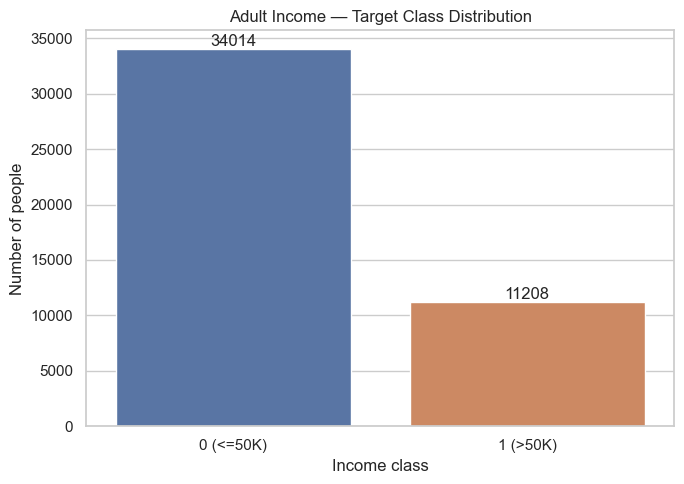

Class proportions:


,proportion
income,
0,0.752156
1,0.247844


In [6]:
print("Original target distribution:")
display(df["income"].value_counts())

df["income"] = (df["income"] == ">50K").astype(int)
print("\nEncoded target distribution:")
display(df["income"].value_counts().sort_index())

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="income", hue="income", legend=False)
ax.set_xticks([0, 1], labels=["0 (<=50K)", "1 (>50K)"])
ax.set_title("Adult Income — Target Class Distribution")
ax.set_xlabel("Income class")
ax.set_ylabel("Number of people")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
save_figure("Task_1_4_target_distribution.png")
plt.show()

class_ratio = df["income"].value_counts(normalize=True).sort_index()
print("Class proportions:")
display(class_ratio.to_frame("proportion"))

## 1.5 Exploratory Data Visualizations

### Task 1.5(a) — Age distribution by income

Compare the age distributions of the two income classes. The plot helps identify whether higher-income observations are concentrated in particular age ranges.

Graph saved: Project_Graphs\Task_1_5a_age_by_income.png


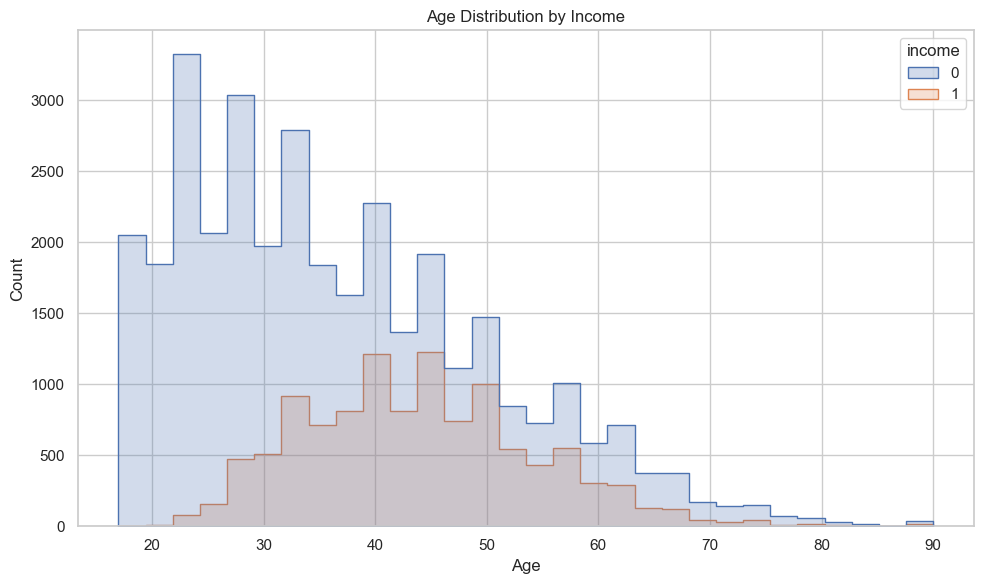

In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="age", hue="income", bins=30, element="step",
             stat="count", common_norm=False)
plt.title("Age Distribution by Income")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
save_figure("Task_1_5a_age_by_income.png")
plt.show()

### Task 1.5(b) — Weekly working hours by income

The boxplot compares the median, spread and outliers of weekly working hours for both income groups.

Graph saved: Project_Graphs\Task_1_5b_hours_boxplot.png


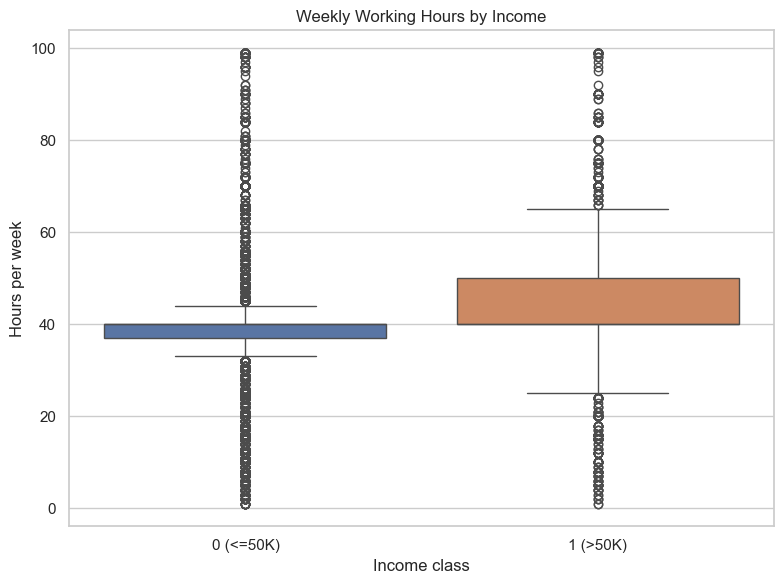

In [8]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="income", y="hours-per-week", hue="income", legend=False)
plt.xticks([0, 1], ["0 (<=50K)", "1 (>50K)"])
plt.title("Weekly Working Hours by Income")
plt.xlabel("Income class")
plt.ylabel("Hours per week")
plt.tight_layout()
save_figure("Task_1_5b_hours_boxplot.png")
plt.show()

## (c) Education Level by Income

Graph saved: Project_Graphs\Task_1_5c_education_countplot.png


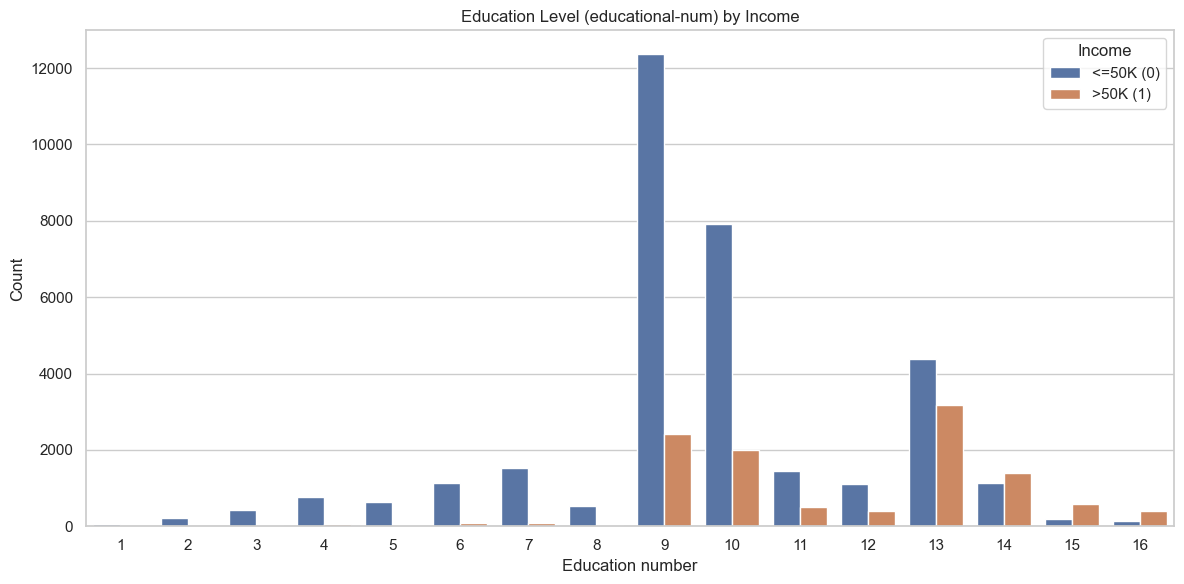

In [9]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x="educational-num", hue="income")
plt.title("Education Level (educational-num) by Income")
plt.xlabel("Education number")
plt.ylabel("Count")
plt.legend(title="Income", labels=["<=50K (0)", ">50K (1)"])
plt.tight_layout()
save_figure("Task_1_5c_education_countplot.png")
plt.show()

### (d) Correlation Heatmap

Graph saved: Project_Graphs\Task_1_5d_correlation_heatmap.png


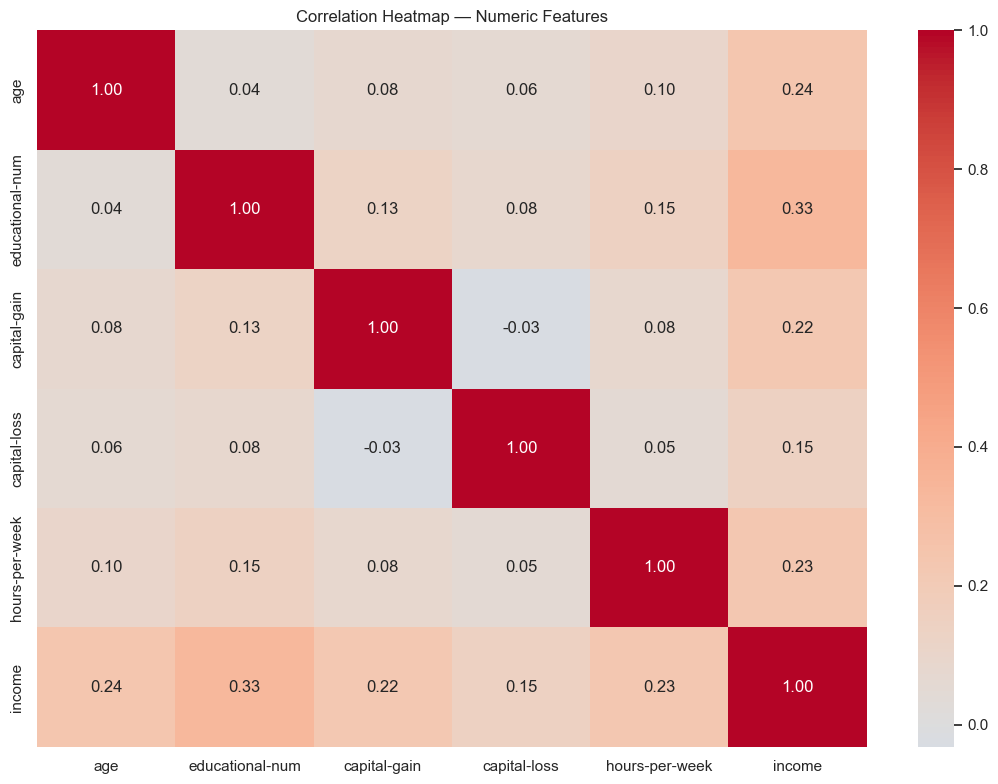

In [10]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(11, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap — Numeric Features")
plt.tight_layout()
save_figure("Task_1_5d_correlation_heatmap.png")
plt.show()

### 1.6 Encode Categorical Features and Scale Numerical Features

In [11]:
X = df.drop(columns=["income"]).copy()
y = df["income"].copy()

X_encoded = pd.get_dummies(X, drop_first=True, dtype=float)
print("Features before one-hot encoding:", X.shape)
print("Features after one-hot encoding:", X_encoded.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=SEED, stratify=y
)

numeric_features = [
    "age", "educational-num", "capital-gain",
    "capital-loss", "hours-per-week"
]
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train.loc[:, numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test.loc[:, numeric_features] = scaler.transform(X_test[numeric_features])

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("proportion"))
print("Testing class proportions:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("proportion"))

input_dim = X_train.shape[1]
print("ANN input dimension:", input_dim)

Features before one-hot encoding: (45222, 12)
Features after one-hot encoding: (45222, 80)
X_train: (36177, 80) | y_train: (36177,)
X_test : (9045, 80) | y_test : (9045,)

Training class proportions:


,proportion
income,
0,0.752163
1,0.247837


Testing class proportions:


,proportion
income,
0,0.752128
1,0.247872


ANN input dimension: 80


<a id="task-2"></a>
# Task 2 — MLP Architecture: Baseline ANN

In [12]:
def build_ann(
    input_dim,
    hidden_units=(128, 64),
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
):
    model = keras.Sequential(name="Adult_Income_ANN")
    model.add(layers.Input(shape=(input_dim,)))

    for units in hidden_units:
        if use_batch_norm:
            model.add(layers.Dense(units, kernel_initializer=initializer))
            model.add(layers.BatchNormalization())
            model.add(layers.Activation(activation))
        else:
            model.add(
                layers.Dense(
                    units,
                    activation=activation,
                    kernel_initializer=initializer
                )
            )

    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=["accuracy"]
    )
    return model

In [12]:
from sklearn.preprocessing import StandardScaler

numeric_features = [
    "age",
    "educational-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train.loc[:, numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

# Transform testing data using the same scaler
X_test.loc[:, numeric_features] = scaler.transform(
    X_test[numeric_features]
)

print("Numerical Features Scaled Successfully!")

print("\nScaled Training Feature Summary:")
display(X_train[numeric_features].describe().round(3))

# Final validation
assert X_train.isnull().sum().sum() == 0
assert X_test.isnull().sum().sum() == 0

print("\nTask 1.6 Completed Successfully!")


Numerical Features Scaled Successfully!

Scaled Training Feature Summary:


,age,educational-num,capital-gain,capital-loss,hours-per-week
count,36177.000,36177.000,36177.000,36177.000,36177.000
mean,-0.000,-0.000,0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000
min,-1.627,-3.555,-0.148,-0.218,-3.320
25%,-0.797,-0.436,-0.148,-0.218,-0.082
50%,-0.117,-0.046,-0.148,-0.218,-0.082
75%,0.638,1.123,-0.148,-0.218,0.333
max,3.886,2.293,13.186,10.549,4.817



Task 1.6 Completed Successfully!


# Task 2.2: Build the Baseline ANN

In [13]:
model_base = build_ann(input_dim=input_dim)
model_base.summary()

manual_params = (
    (input_dim * 128 + 128) +
    (128 * 64 + 64) +
    (64 * 1 + 1)
)
print("Manually calculated trainable parameters:", manual_params)

Model: "Adult_Income_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

Manually calculated trainable parameters: 18689


# Task 2.3: Train the Baseline ANN

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8414 - loss: 0.3389 - val_accuracy: 0.8485 - val_loss: 0.3210
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8533 - loss: 0.3148 - val_accuracy: 0.8477 - val_loss: 0.3205
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8554 - loss: 0.3110 - val_accuracy: 0.8488 - val_loss: 0.3198
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8569 - loss: 0.3081 - val_accuracy: 0.8491 - val_loss: 0.3193
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8583 - loss: 0.3054 - val_accuracy: 0.8485 - val_loss: 0.3195
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8599 - loss: 0.3030 - val_accuracy: 0.8483 - val_loss: 0.3196
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8612 - loss: 0.3006 - val_accuracy: 0.8505 - val_loss: 0.3190
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8625 - loss: 0.2983 - val_accuracy: 0.

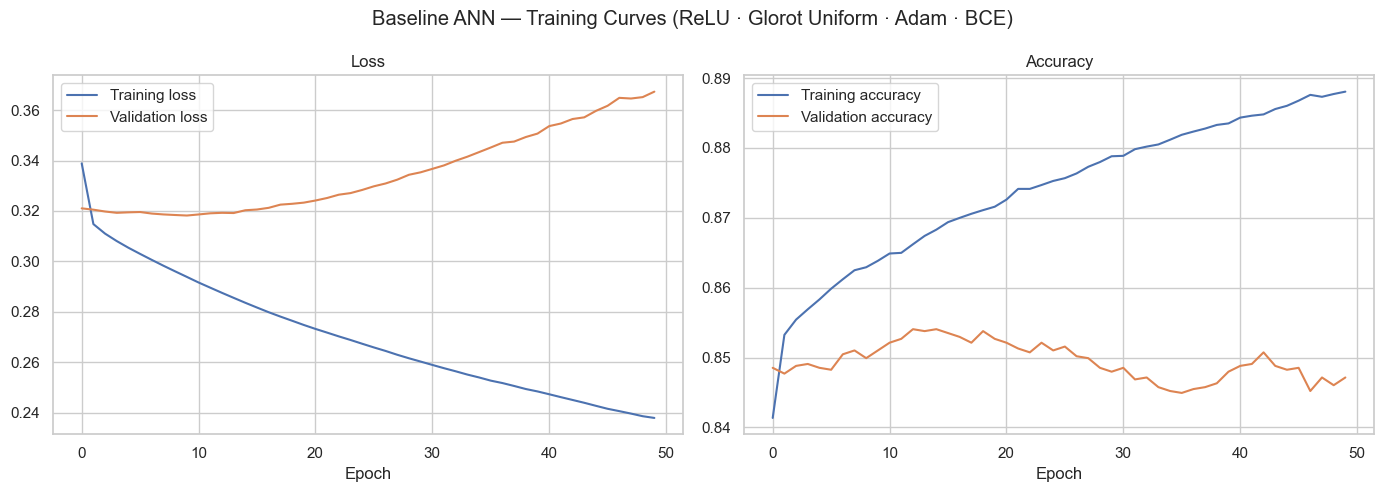

In [14]:
keras.utils.set_random_seed(SEED)
history_base = model_base.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_base.history["loss"], label="Training loss")
axes[0].plot(history_base.history["val_loss"], label="Validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history_base.history["accuracy"], label="Training accuracy")
axes[1].plot(history_base.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
fig.suptitle("Baseline ANN — Training Curves (ReLU · Glorot Uniform · Adam · BCE)")
plt.tight_layout()
save_figure("Task_2_3_baseline_training_curves.png")
plt.show()

## Task 2.4 — Evaluate baseline with full metrics

Class 1 (`>50K`) is the minority class. Its precision, recall and F1-score are especially important and will be included in the final comparison.

              precision    recall  f1-score   support

   <=50K (0)       0.87      0.92      0.89      6803
    >50K (1)       0.71      0.58      0.64      2242

    accuracy                           0.84      9045
   macro avg       0.79      0.75      0.77      9045
weighted avg       0.83      0.84      0.83      9045



,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
Model,,,,,
Baseline,0.836705,0.707768,0.581178,0.638256,0.887126


Graph saved: Project_Graphs\Task_2_4_baseline_confusion_matrix.png


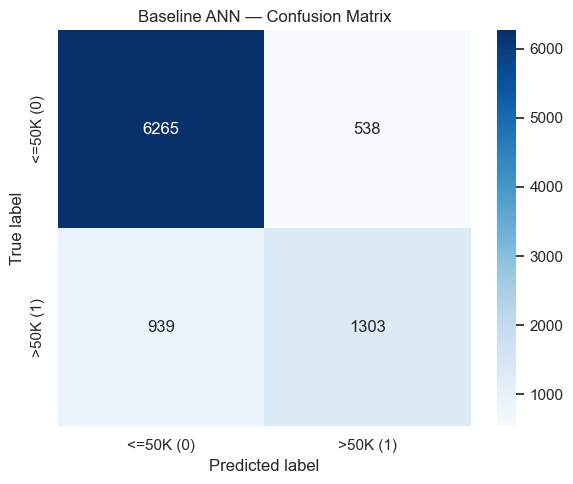

In [15]:
def predict_metrics(model, X_eval, y_eval, threshold=0.5, model_name="Model"):
    probabilities = model.predict(X_eval, verbose=0).ravel()
    predictions = (probabilities >= threshold).astype(int)
    metrics = {
        "Model": model_name,
        "Test Acc": accuracy_score(y_eval, predictions),
        "Prec(1)": precision_score(y_eval, predictions, pos_label=1, zero_division=0),
        "Recall(1)": recall_score(y_eval, predictions, pos_label=1, zero_division=0),
        "F1(1)": f1_score(y_eval, predictions, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, probabilities)
    }
    return metrics, probabilities, predictions

baseline_metrics, baseline_prob, baseline_pred = predict_metrics(
    model_base, X_test, y_test, model_name="Baseline"
)
print(classification_report(y_test, baseline_pred, target_names=["<=50K (0)", ">50K (1)"]))
display(pd.DataFrame([baseline_metrics]).set_index("Model"))

cm = confusion_matrix(y_test, baseline_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["<=50K (0)", ">50K (1)"],
            yticklabels=["<=50K (0)", ">50K (1)"])
plt.title("Baseline ANN — Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
save_figure("Task_2_4_baseline_confusion_matrix.png")
plt.show()

### Task 2.5: Why Tabular Data Suits ANN

**Objective:**

The Adult Income Dataset contains structured tabular data with numerical and categorical features. A fully connected Multi-Layer Perceptron (MLP) is suitable for learning patterns from this type of data.

**Why is ANN suitable for tabular data?**

1. Each input neuron receives one numerical or encoded feature from the dataset.
2. The hidden layers learn weighted combinations of different input features.
3. ReLU activation helps the network learn non-linear relationships.
4. The network can learn feature interactions such as age × education and hours-per-week × occupation.
5. The sigmoid output layer predicts the probability of an individual's income class.

Unlike CNNs, which are commonly used for image data, and RNNs, which are commonly used for sequential data, a fully connected MLP is appropriate for structured demographic and employment information.

**Conclusion:**

ANN is suitable for the Adult Income Dataset because it can learn complex relationships and non-linear patterns between demographic, educational, and employment features to predict income categories.


## Task 3: Activation Function Comparison

### 3.1 Train ANN Models with Different Activation Functions

**Objective:** Compare ReLU, Tanh, and Sigmoid activation functions in the hidden layers of the baseline ANN.

**Architecture:** Input Layer → Dense(128) → Dense(64) → Output Layer(1, Sigmoid)

**Experimental settings:**
- Epochs: 50
- Batch size: 64
- Validation split: 10%
- Optimizer: Adam
- Loss function: Binary Cross-Entropy
- Weight initializer: Glorot Uniform

**Expected output:** Training histories for all three activation functions, ready for comparison.


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# Split the training data into training and validation sets
X_ann_train, X_ann_val, y_ann_train, y_ann_val = train_test_split(
    X_train,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_ann_train.shape)
print("Validation data:", X_ann_val.shape)

Training data: (32559, 80)
Validation data: (3618, 80)


## Task 3.1 — Train four models with different hidden activations

Compare ReLU, tanh, sigmoid and ELU. All other settings remain at the baseline defaults. Each model trains for 50 epochs.

In [17]:
activation_functions = ["relu", "tanh", "sigmoid", "elu"]
activation_models = {}
activation_histories = {}

for activation_name in activation_functions:
    print(f"Training activation: {activation_name}")
    keras.utils.set_random_seed(SEED)
    model = build_ann(input_dim=input_dim, activation=activation_name)
    history = model.fit(
        X_train, y_train,
        epochs=50, batch_size=64,
        validation_split=0.1, verbose=0
    )
    activation_models[activation_name] = model
    activation_histories[activation_name] = history

print("All four activation models completed.")

Training activation: relu
Training activation: tanh
Training activation: sigmoid
Training activation: elu
All four activation models completed.


# Task 3.2: Four-Panel Activation Comparison

Graph saved: Project_Graphs\Task_3_2_activation_comparison.png


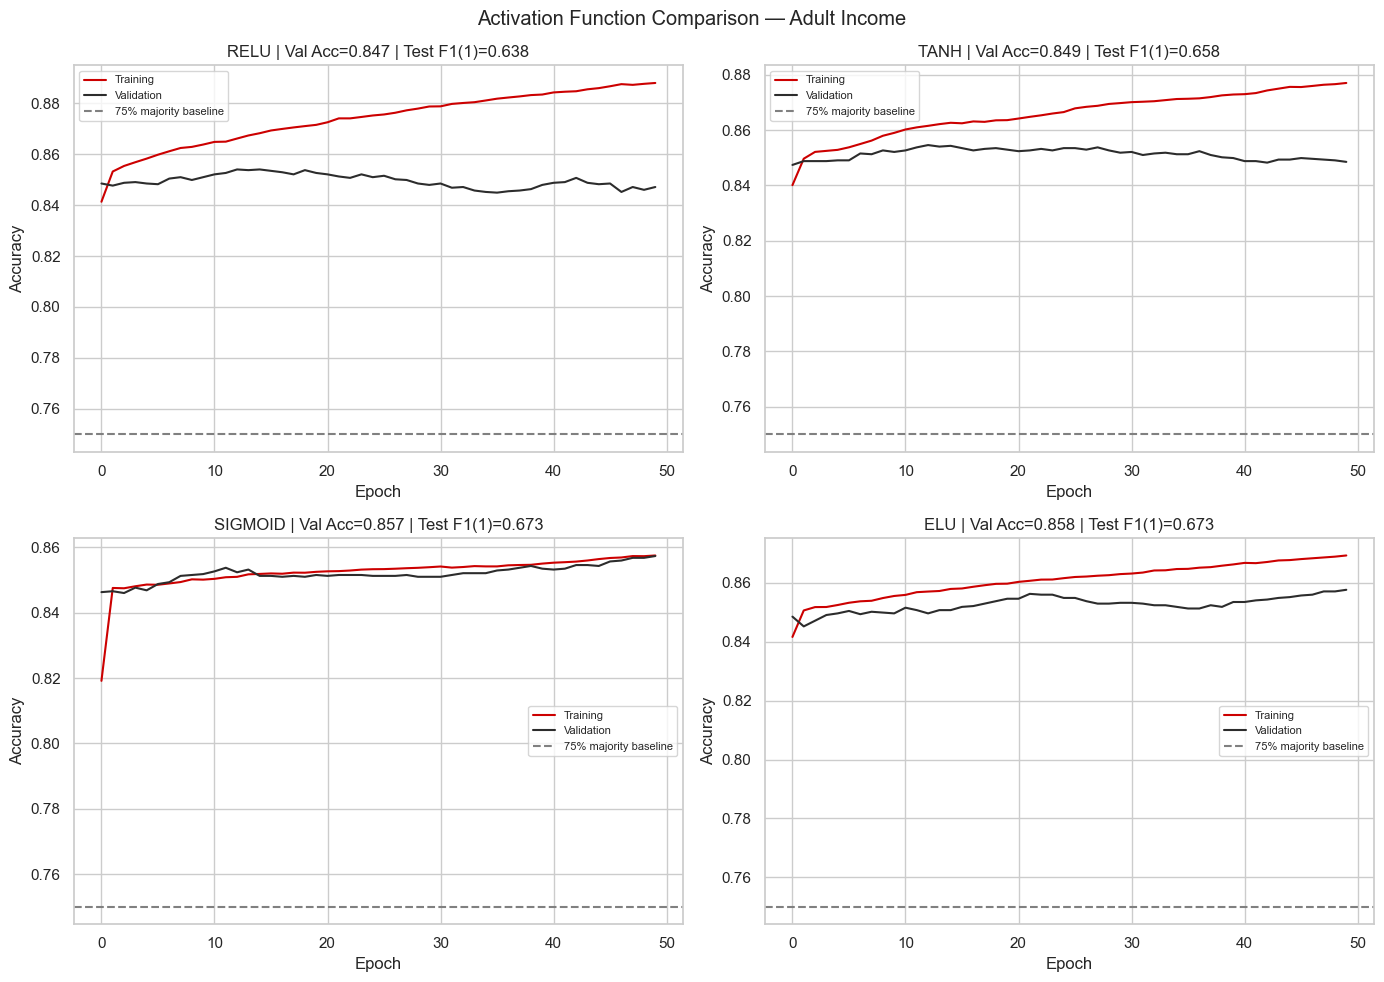

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, activation_name in zip(axes.flat, activation_functions):
    hist = activation_histories[activation_name]
    metrics, _, _ = predict_metrics(
        activation_models[activation_name], X_test, y_test,
        model_name=activation_name
    )
    ax.plot(hist.history["accuracy"], color="#CC0000", label="Training")
    ax.plot(hist.history["val_accuracy"], color="#2C2C2C", label="Validation")
    ax.axhline(0.75, color="gray", linestyle="--", label="75% majority baseline")
    ax.set_title(
        f"{activation_name.upper()} | Val Acc={hist.history['val_accuracy'][-1]:.3f} "
        f"| Test F1(1)={metrics['F1(1)']:.3f}"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend(fontsize=8)
fig.suptitle("Activation Function Comparison — Adult Income")
plt.tight_layout()
save_figure("Task_3_2_activation_comparison.png")
plt.show()

### 3.3 ReLU Dead-Neuron Check

In [25]:
# Select the trained ReLU model
relu_model = activation_models["relu"]

# Explicitly build the model with input shape
input_dim = X_train.shape[1]
relu_model.build((None, input_dim))

# Get the first hidden Dense layer
first_dense = next(
    layer for layer in relu_model.layers
    if isinstance(layer, layers.Dense)
)

# Create intermediate model using explicit input tensor
input_tensor = keras.Input(shape=(input_dim,))

output_tensor = relu_model(input_tensor, training=False)

intermediate_model = keras.Model(
    inputs=input_tensor,
    outputs=first_dense(input_tensor)
)

# Select 500 test samples
X_sample = X_test.iloc[:500]

# Get first hidden layer activations
activation_values = intermediate_model.predict(
    X_sample,
    verbose=0
)

# Calculate zero activation fraction
dead_fraction = np.mean(activation_values == 0)

# Calculate mean activation per neuron
mean_activation_per_neuron = activation_values.mean(axis=0)

# Count neurons that are zero for all 500 samples
dead_neuron_count = np.sum(
    np.all(activation_values == 0, axis=0)
)

print("Activation output shape:", activation_values.shape)

print(f"Zero activation fraction: {dead_fraction:.4f}")

print(f"Zero activation percentage: {dead_fraction * 100:.2f}%")

print("Total neurons:", activation_values.shape[1])

print("Potential dead neurons:", dead_neuron_count)

Activation output shape: (500, 128)
Zero activation fraction: 0.6181
Zero activation percentage: 61.81%
Total neurons: 128
Potential dead neurons: 0


## Task 3.4 — Gradient flow check for sigmoid hidden layers

Use `GradientTape` to calculate mean absolute gradients for each Dense layer on one training batch. Very small early-layer gradients compared with the output layer indicate vanishing-gradient behaviour.

Graph saved: Project_Graphs\Task_3_4_sigmoid_gradient_magnitude.png


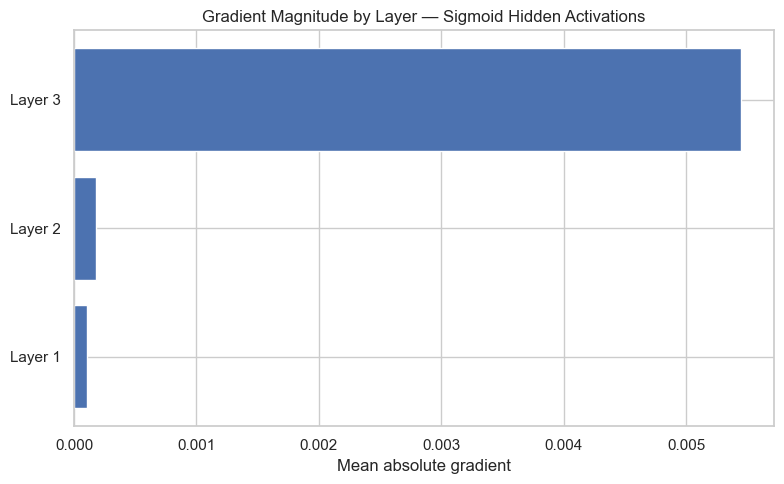

,Dense layer,Mean absolute gradient
0,Layer 1,0.000104
1,Layer 2,0.000180
2,Layer 3,0.005445


In [26]:
sigmoid_model = activation_models["sigmoid"]
x_batch = tf.convert_to_tensor(X_train.iloc[:256].to_numpy(), dtype=tf.float32)
y_batch = tf.convert_to_tensor(y_train.iloc[:256].to_numpy().reshape(-1, 1), dtype=tf.float32)

with tf.GradientTape() as tape:
    predictions = sigmoid_model(x_batch, training=True)
    batch_loss = tf.reduce_mean(
        keras.losses.binary_crossentropy(y_batch, predictions)
    )

dense_layers = [layer for layer in sigmoid_model.layers if isinstance(layer, layers.Dense)]
gradients = tape.gradient(batch_loss, [layer.kernel for layer in dense_layers])
gradient_means = [
    float(tf.reduce_mean(tf.abs(grad)).numpy()) if grad is not None else 0.0
    for grad in gradients
]
gradient_labels = [f"Layer {i+1}" for i in range(len(gradient_means))]

plt.figure(figsize=(8, 5))
plt.barh(gradient_labels, gradient_means)
plt.xlabel("Mean absolute gradient")
plt.title("Gradient Magnitude by Layer — Sigmoid Hidden Activations")
plt.tight_layout()
save_figure("Task_3_4_sigmoid_gradient_magnitude.png")
plt.show()

display(pd.DataFrame({"Dense layer": gradient_labels,
                      "Mean absolute gradient": gradient_means}))

## Task 3.5: Activation Function Summary

The following table compares different activation functions based on their mathematical formula, output range, zero-centering, vanishing gradient risk, and dead neuron risk.

| Activation | Formula | Output Range | Zero-Centred | Vanishing Gradient Risk | Dead Neuron Risk | Val Accuracy on Adult |
|---|---|---|---|---|---|---|
| ReLU | max(0, x) | [0, ∞) | No | Low for positive inputs | Yes | Fill from results |
| Tanh | tanh(x) | (-1, 1) | Yes | Yes | No | Fill from results |
| Sigmoid (Hidden) | 1 / (1 + e⁻ˣ) | (0, 1) | No | High | No | Fill from results |
| ELU | x if x > 0, else α(eˣ − 1) | (-α, ∞) | Approximately | Low compared to sigmoid | Low | Fill from results |
| Sigmoid (Output only) | 1 / (1 + e⁻ˣ) | (0, 1) | No | Output-layer saturation possible | No | N/A |


In [27]:
activation_summary = []
for activation_name in activation_functions:
    hist = activation_histories[activation_name]
    metrics, _, _ = predict_metrics(
        activation_models[activation_name], X_test, y_test,
        model_name=activation_name
    )
    activation_summary.append({
        "Activation": activation_name,
        "Formula": {
            "relu": "max(0, x)",
            "tanh": "(e^x - e^(-x)) / (e^x + e^(-x))",
            "sigmoid": "1 / (1 + e^(-x))",
            "elu": "x if x > 0 else alpha * (e^x - 1)"
        }[activation_name],
        "Output range": {
            "relu": "[0, infinity)", "tanh": "(-1, 1)",
            "sigmoid": "(0, 1)", "elu": "(-alpha, infinity)"
        }[activation_name],
        "Zero-centred": activation_name == "tanh",
        "Vanishing-gradient risk": "Higher" if activation_name == "sigmoid" else
                                   ("Some" if activation_name == "tanh" else "Lower"),
        "Dead-neuron risk": "Yes" if activation_name == "relu" else "Low",
        "Val Accuracy": hist.history["val_accuracy"][-1],
        "Test F1(1)": metrics["F1(1)"]
    })
activation_summary_df = pd.DataFrame(activation_summary)
display(activation_summary_df.sort_values("Test F1(1)", ascending=False))
print("Recommendation: select the activation based on the measured validation/test results; "
      "ReLU is a strong default for hidden layers, while sigmoid remains appropriate for the binary output.")

,Activation,Formula,Output range,Zero-centred,Vanishing-gradient risk,Dead-neuron risk,Val Accuracy,Test F1(1)
2,sigmoid,1 / (1 + e^(-x)),"(0, 1)",False,Higher,Low,0.857380,0.673224
3,elu,x if x > 0 else alpha * (e^x - 1),"(-alpha, infinity)",False,Lower,Low,0.857656,0.672947
1,tanh,(e^x - e^(-x)) / (e^x + e^(-x)),"(-1, 1)",True,Some,Low,0.848535,0.658166
0,relu,"max(0, x)","[0, infinity)",False,Lower,Yes,0.847153,0.638256


Recommendation: select the activation based on the measured validation/test results; ReLU is a strong default for hidden layers, while sigmoid remains appropriate for the binary output.



## Task 4: Weight Initialization Techniques

# Task 4.1: Train 5 Models with Different Weight Initializers
Compare Glorot Uniform, Glorot Normal, He Uniform, He Normal and Zeros. Other settings remain at baseline defaults.

In [31]:
# Task 4.1 — Train ANN with Different Weight Initializers

initializers = [
    "glorot_uniform",
    "glorot_normal",
    "he_uniform",
    "he_normal",
    "zeros"
]

initializer_models = {}
initializer_histories = {}

for initializer_name in initializers:

    print(f"\nTraining with {initializer_name} initializer...")

    keras.utils.set_random_seed(42)

    model = build_ann(
        input_dim=X_train.shape[1],
        hidden_units=[128, 64],
        activation="relu",
        initializer=initializer_name,
        use_batch_norm=False,
        optimizer="adam",
        loss="binary_crossentropy"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    initializer_models[initializer_name] = model
    initializer_histories[initializer_name] = history

    print(f"{initializer_name} training completed!")

print("\nAll five initializer models trained successfully!")


Training with glorot_uniform initializer...
glorot_uniform training completed!

Training with glorot_normal initializer...
glorot_normal training completed!

Training with he_uniform initializer...
he_uniform training completed!

Training with he_normal initializer...
he_normal training completed!

Training with zeros initializer...
zeros training completed!

All five initializer models trained successfully!


## Task 4.2 — Why initialization matters

In [32]:
initializer_names = [
    "glorot_uniform", "glorot_normal",
    "he_uniform", "he_normal", "zeros"
]
initializer_models = {}
initializer_histories = {}
initializer_initial_weights = {}

for initializer_name in initializer_names:
    print(f"Training initializer: {initializer_name}")
    keras.utils.set_random_seed(SEED)
    model = build_ann(input_dim=input_dim, activation="relu",
                      initializer=initializer_name)
    first_dense_layer = next(layer for layer in model.layers if isinstance(layer, layers.Dense))
    initializer_initial_weights[initializer_name] = first_dense_layer.get_weights()[0].copy()
    history = model.fit(
        X_train, y_train,
        epochs=50, batch_size=64,
        validation_split=0.1, verbose=0
    )
    initializer_models[initializer_name] = model
    initializer_histories[initializer_name] = history

print("All five initializer models completed.")

Training initializer: glorot_uniform
Training initializer: glorot_normal
Training initializer: he_uniform
Training initializer: he_normal
Training initializer: zeros
All five initializer models completed.


# Task 4.3: Convergence Speed Comparison

glorot_uniform: First reached 82% validation accuracy at epoch 1
glorot_normal: First reached 82% validation accuracy at epoch 1
he_uniform: First reached 82% validation accuracy at epoch 1
he_normal: First reached 82% validation accuracy at epoch 1
zeros: Did not reach 82% validation accuracy
Graph saved: Project_Graphs\Task_4_3_initializer_convergence.png


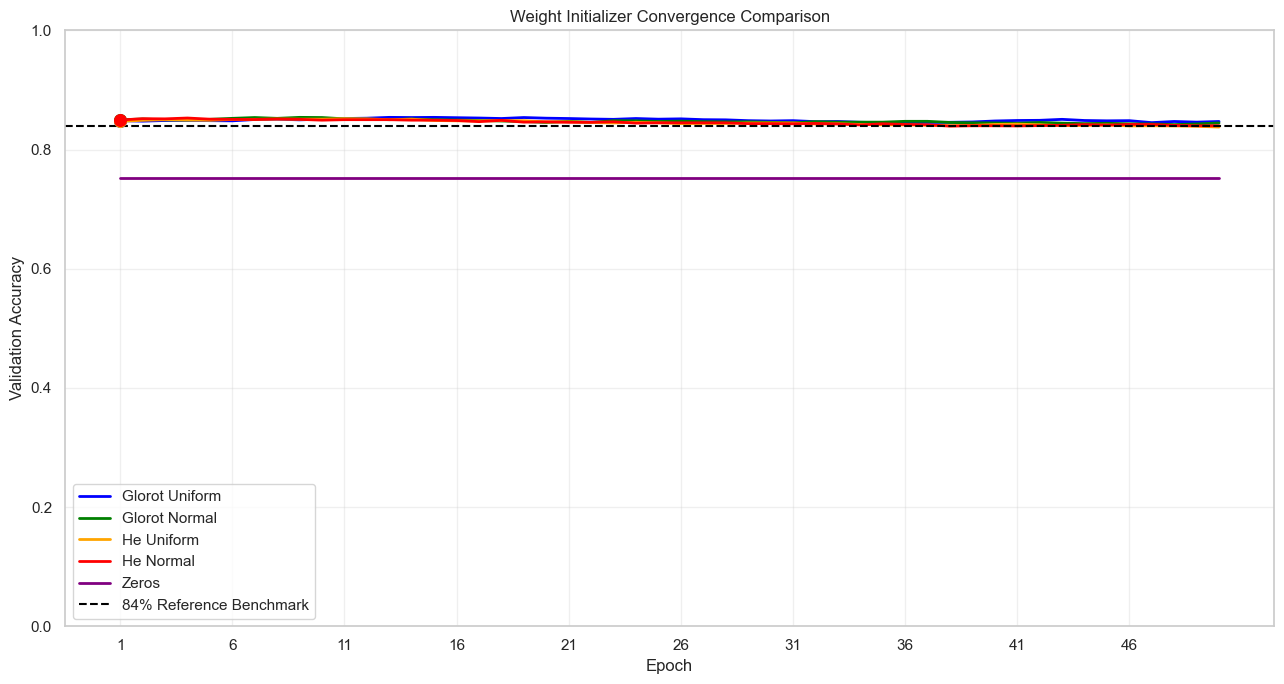

In [33]:
# Task 4.3 — Compare Validation Accuracy of Initializers

plt.figure(figsize=(13, 7))

initializer_colors = {
    "glorot_uniform": "blue",
    "glorot_normal": "green",
    "he_uniform": "orange",
    "he_normal": "red",
    "zeros": "purple"
}

for initializer_name in initializers:

    history = initializer_histories[initializer_name]

    val_accuracy = history.history["val_accuracy"]

    epochs = range(1, len(val_accuracy) + 1)

    # Plot validation accuracy
    plt.plot(
        epochs,
        val_accuracy,
        label=initializer_name.replace("_", " ").title(),
        color=initializer_colors[initializer_name],
        linewidth=2
    )

    # Find first epoch where validation accuracy reaches 82%
    crossing_epochs = [
        epoch
        for epoch, accuracy in zip(epochs, val_accuracy)
        if accuracy >= 0.82
    ]

    if crossing_epochs:

        first_epoch = crossing_epochs[0]

        print(
            f"{initializer_name}: First reached 82% "
            f"validation accuracy at epoch {first_epoch}"
        )

        plt.scatter(
            first_epoch,
            val_accuracy[first_epoch - 1],
            s=70,
            color=initializer_colors[initializer_name],
            zorder=5
        )

    else:
        print(
            f"{initializer_name}: Did not reach 82% "
            "validation accuracy"
        )

# 84% reference benchmark
plt.axhline(
    y=0.84,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="84% Reference Benchmark"
)

plt.title("Weight Initializer Convergence Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.xticks(range(1, 51, 5))
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

save_figure("Task_4_3_initializer_convergence.png")

plt.show()


## Task 4.4 — Demonstrate failure of zero initialization

Plot the zero-initialized model's training loss and validation accuracy. Because neurons start symmetrically, the network cannot learn distinct feature representations.

Graph saved: Project_Graphs\Task_4_4_zero_initialization_failure.png


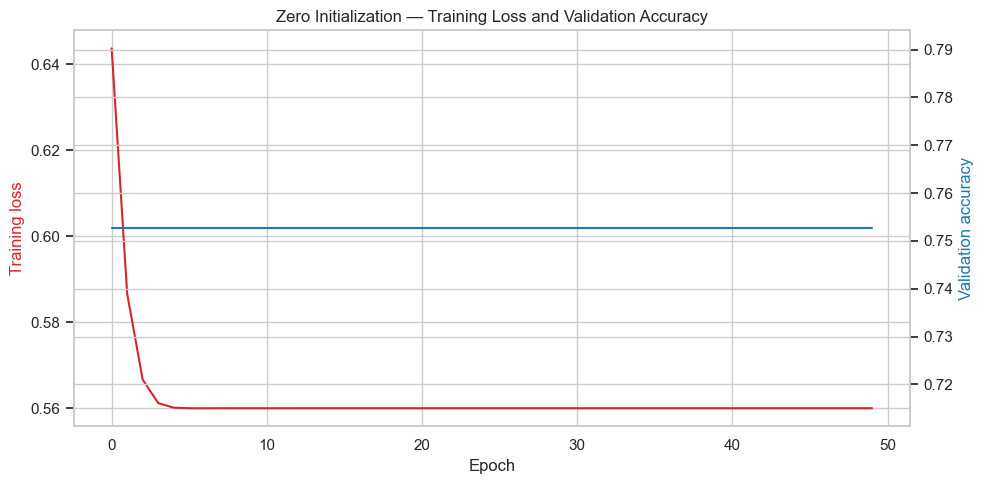

In [34]:
zero_history = initializer_histories["zeros"]
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(zero_history.history["loss"], color="tab:red", label="Training loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Training loss", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(zero_history.history["val_accuracy"], color="tab:blue",
         label="Validation accuracy")
ax2.set_ylabel("Validation accuracy", color="tab:blue")
plt.title("Zero Initialization — Training Loss and Validation Accuracy")
fig.tight_layout()
save_figure("Task_4_4_zero_initialization_failure.png")
plt.show()

## Task 4.5 — Visualize initial vs trained weight distributions

Compare first-layer weights before training and after 50 epochs for He Normal and Glorot Uniform.

Graph saved: Project_Graphs\Task_4_5_weight_distributions.png


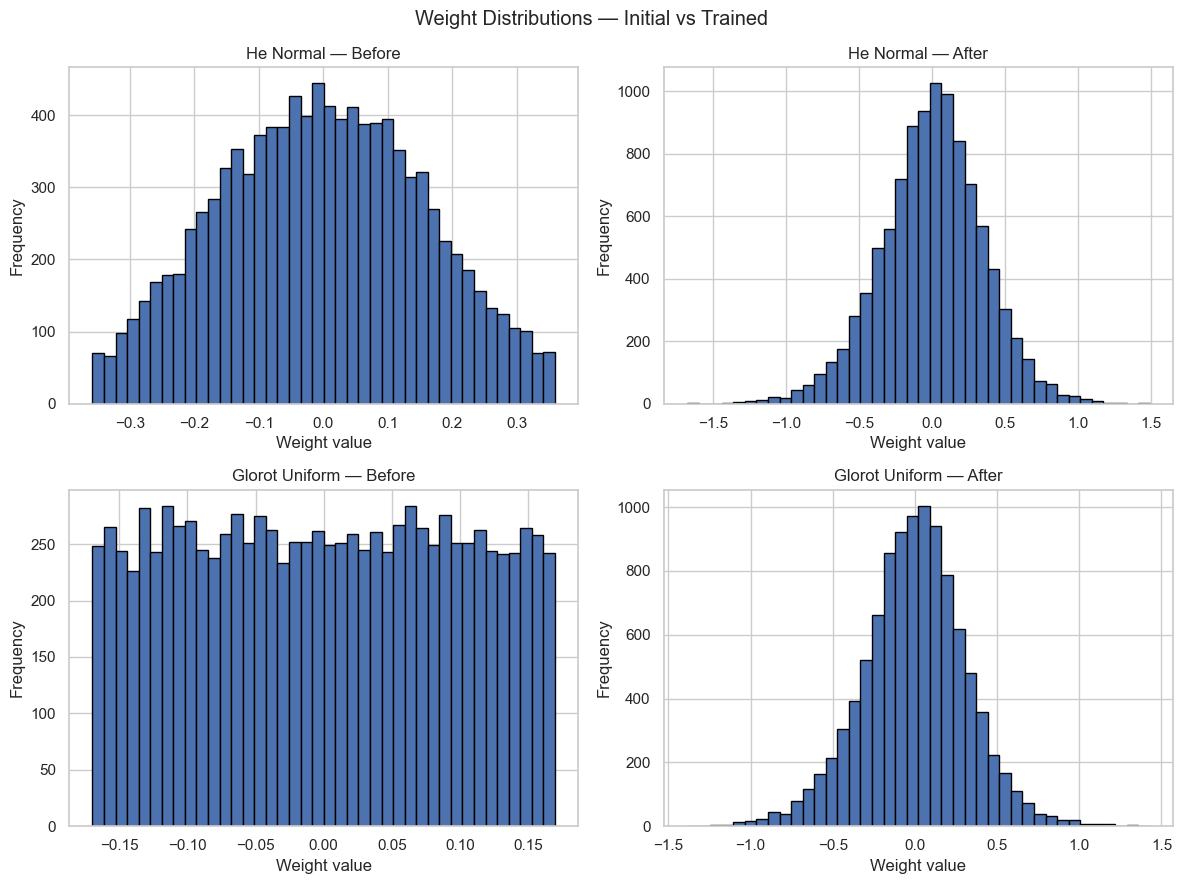

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
weight_cases = [
    ("he_normal", "He Normal — Before", initializer_initial_weights["he_normal"]),
    ("he_normal", "He Normal — After", next(
        layer for layer in initializer_models["he_normal"].layers
        if isinstance(layer, layers.Dense)
    ).get_weights()[0]),
    ("glorot_uniform", "Glorot Uniform — Before", initializer_initial_weights["glorot_uniform"]),
    ("glorot_uniform", "Glorot Uniform — After", next(
        layer for layer in initializer_models["glorot_uniform"].layers
        if isinstance(layer, layers.Dense)
    ).get_weights()[0])
]
for ax, (_, title, weights) in zip(axes.flat, weight_cases):
    ax.hist(np.asarray(weights).ravel(), bins=40, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Frequency")
fig.suptitle("Weight Distributions — Initial vs Trained")
plt.tight_layout()
save_figure("Task_4_5_weight_distributions.png")
plt.show()


# Task 5: Loss Functions

### 5.1 Binary Cross-Entropy (BCE) — Baseline Loss

**Objective:** Understand why Binary Cross-Entropy is appropriate for binary classification.

The baseline ANN uses `binary_crossentropy` as its loss function. The target variable `income` has two classes:

- `0` = Income <=50K
- `1` = Income >50K

**Formula:**

\[
L=-[y\log(p)+(1-y)\log(1-p)]
\]

Where:
- \(y\) is the actual class label (0 or 1).
- \(p\) is the predicted probability of class 1.
- \(L\) is the loss for one observation.

**Why BCE?**

1. It is designed for binary classification.
2. It penalizes confident incorrect predictions strongly.
3. It works naturally with a sigmoid output, which produces probabilities between 0 and 1.
4. It corresponds to the negative log-likelihood of a Bernoulli outcome.

**Conclusion:** BCE is a suitable baseline loss for predicting whether annual income exceeds $50,000.


In [36]:

print("Baseline model loss function:", model_base.loss)

print("\nBaseline model output activation:")
print(model_base.layers[-1].get_config()["activation"])

print("\nTarget classes:")
print("0 = Income <=50K")
print("1 = Income >50K")


Baseline model loss function: binary_crossentropy

Baseline model output activation:
sigmoid

Target classes:
0 = Income <=50K
1 = Income >50K


## Task 5.2 — MSE as a classification loss experiment

Train a model with mean squared error while keeping the sigmoid output. Track validation F1 for class 1 for both BCE and MSE using a fixed validation subset carved from the training data.

Graph saved: Project_Graphs\Task_5_2_mse_vs_bce_validation_f1.png


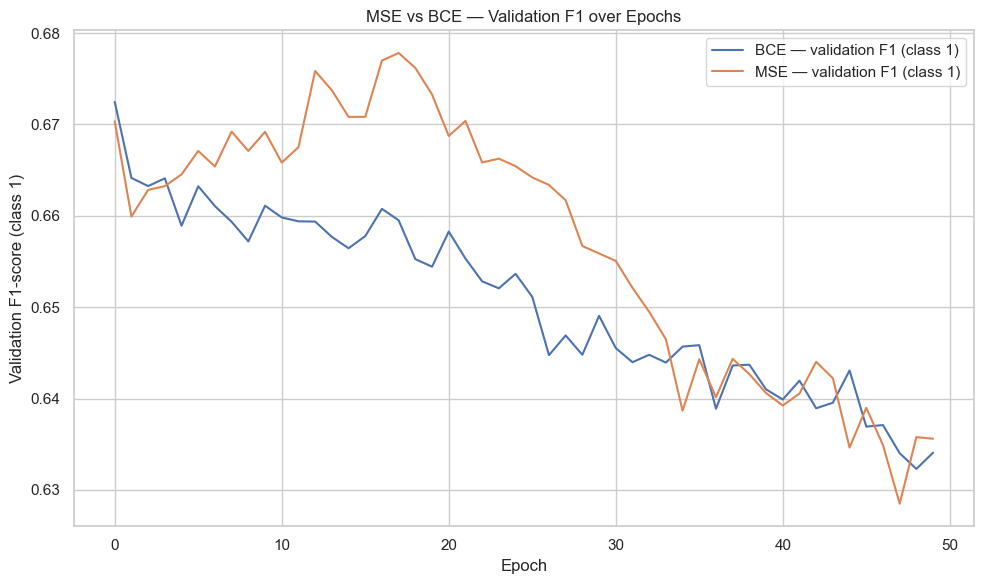

In [37]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=SEED, stratify=y_train
)

class ValidationF1Callback(keras.callbacks.Callback):
    def __init__(self, x_val, y_val):
        super().__init__()
        self.x_val = x_val
        self.y_val = np.asarray(y_val)
        self.val_f1 = []

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.x_val, verbose=0).ravel()
        preds = (probs >= 0.5).astype(int)
        self.val_f1.append(
            f1_score(self.y_val, preds, pos_label=1, zero_division=0)
        )

# Re-train a BCE comparison model using the same fixed validation subset.
keras.utils.set_random_seed(SEED)
model_bce_f1 = build_ann(input_dim=input_dim)
bce_f1_callback = ValidationF1Callback(X_val, y_val)
history_bce_f1 = model_bce_f1.fit(
    X_fit, y_fit, epochs=50, batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[bce_f1_callback], verbose=0
)

keras.utils.set_random_seed(SEED)
model_mse = build_ann(input_dim=input_dim, activation="relu",
                      initializer="he_normal", loss="mean_squared_error")
mse_f1_callback = ValidationF1Callback(X_val, y_val)
history_mse = model_mse.fit(
    X_fit, y_fit, epochs=50, batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[mse_f1_callback], verbose=0
)

plt.figure(figsize=(10, 6))
plt.plot(bce_f1_callback.val_f1, label="BCE — validation F1 (class 1)")
plt.plot(mse_f1_callback.val_f1, label="MSE — validation F1 (class 1)")
plt.xlabel("Epoch")
plt.ylabel("Validation F1-score (class 1)")
plt.title("MSE vs BCE — Validation F1 over Epochs")
plt.legend()
plt.tight_layout()
save_figure("Task_5_2_mse_vs_bce_validation_f1.png")
plt.show()

# Task 5.3: Calculate Balanced Class Weights

In [38]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

class_values = np.array([0, 1])
weights = compute_class_weight(class_weight="balanced",
                               classes=class_values,
                               y=np.asarray(y_train))
class_weight_dict = {0: float(weights[0]), 1: float(weights[1])}
print("Class weights:", class_weight_dict)

keras.utils.set_random_seed(SEED)
model_wbce = build_ann(
    input_dim=input_dim, activation="relu",
    initializer="he_normal", loss="binary_crossentropy"
)
history_wbce = model_wbce.fit(
    X_train, y_train, epochs=50, batch_size=64,
    validation_split=0.1, class_weight=class_weight_dict,
    verbose=0
)
print("Weighted BCE model training completed.")


Class weights: {0: 0.6647495498144133, 1: 2.0174548293553425}
Weighted BCE model training completed.


### Compare class-1 Precision, Recall and F1

,Prec(1),Recall(1),F1(1)
Model,,,
Baseline BCE,0.707768,0.581178,0.638256
Weighted BCE,0.565618,0.793934,0.660605


Graph saved: Project_Graphs\Task_5_3_weighted_bce_metrics.png


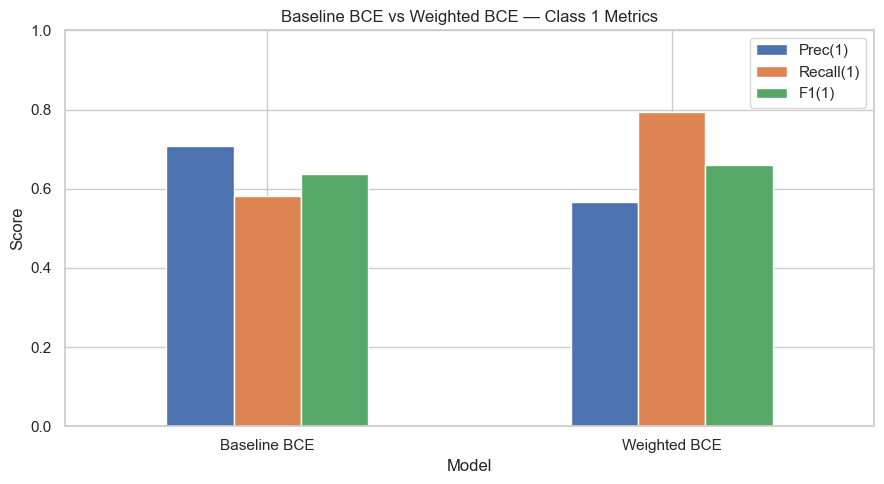

In [39]:
base_compare, _, _ = predict_metrics(model_base, X_test, y_test, model_name="Baseline BCE")
weighted_compare, _, _ = predict_metrics(model_wbce, X_test, y_test, model_name="Weighted BCE")
metric_comparison = pd.DataFrame([base_compare, weighted_compare]).set_index("Model")
display(metric_comparison[["Prec(1)", "Recall(1)", "F1(1)"]])

metric_comparison[["Prec(1)", "Recall(1)", "F1(1)"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
plt.title("Baseline BCE vs Weighted BCE — Class 1 Metrics")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
save_figure("Task_5_3_weighted_bce_metrics.png")
plt.show()

## Task 5.4 — Focal Loss: advanced imbalance handling

Focal Loss down-weights easy examples and focuses learning on hard examples. The implementation below uses `gamma=2.0` and `alpha=0.25`, as specified.

In [40]:
import tensorflow as tf
from tensorflow import keras

def focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        bce = -y_true * tf.math.log(y_pred) - (
            1.0 - y_true
        ) * tf.math.log(1.0 - y_pred)
        weight = (
            alpha * y_true * tf.pow(1.0 - y_pred, gamma) +
            (1.0 - alpha) * (1.0 - y_true) * tf.pow(y_pred, gamma)
        )
        return tf.reduce_mean(weight * bce)
    return loss

keras.utils.set_random_seed(SEED)
model_focal = build_ann(
    input_dim=input_dim, activation="relu",
    initializer="he_normal", loss=focal_loss(gamma=2.0, alpha=0.25)
)
history_focal = model_focal.fit(
    X_train, y_train, epochs=50, batch_size=64,
    validation_split=0.1, verbose=0
)
print("Focal Loss model training completed.")


Focal Loss model training completed.


# Task 5.4: Train Focal Loss Model

In [41]:
def focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        bce = -y_true * tf.math.log(y_pred) - (
            1.0 - y_true
        ) * tf.math.log(1.0 - y_pred)
        weight = (
            alpha * y_true * tf.pow(1.0 - y_pred, gamma) +
            (1.0 - alpha) * (1.0 - y_true) * tf.pow(y_pred, gamma)
        )
        return tf.reduce_mean(weight * bce)
    return loss

keras.utils.set_random_seed(SEED)
model_focal = build_ann(
    input_dim=input_dim, activation="relu",
    initializer="he_normal", loss=focal_loss(gamma=2.0, alpha=0.25)
)
history_focal = model_focal.fit(
    X_train, y_train, epochs=50, batch_size=64,
    validation_split=0.1, verbose=0
)
print("Focal Loss model training completed.")

Focal Loss model training completed.


# Task 5.4: Compare BCE, Weighted BCE and Focal Loss

,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
Model,,,,,
Baseline BCE,0.836705,0.707768,0.581178,0.638256,0.887126
Weighted BCE,0.797789,0.565618,0.793934,0.660605,0.883465
Focal Loss,0.819016,0.753562,0.400981,0.523435,0.875198


Graph saved: Project_Graphs\Task_5_4_loss_function_comparison.png


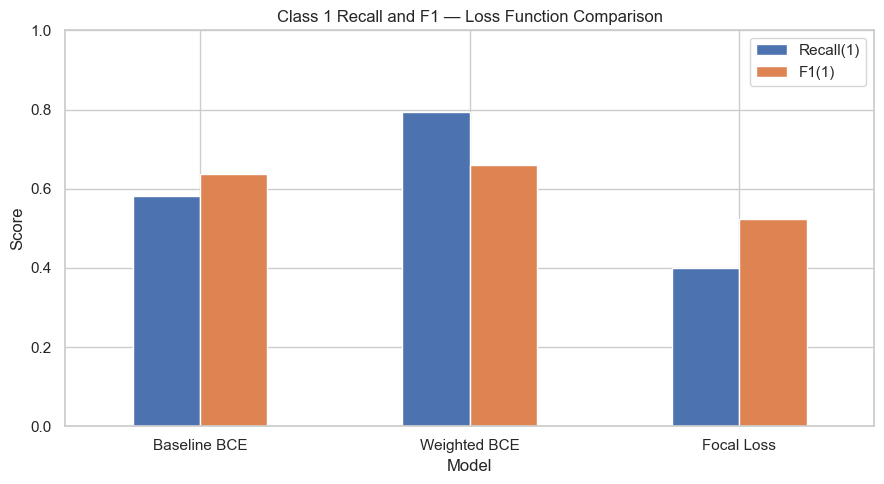

In [42]:
loss_models = {
    "Baseline BCE": model_base,
    "Weighted BCE": model_wbce,
    "Focal Loss": model_focal
}
loss_metric_rows = []
for name, model in loss_models.items():
    row, _, _ = predict_metrics(model, X_test, y_test, model_name=name)
    loss_metric_rows.append(row)
loss_metrics_df = pd.DataFrame(loss_metric_rows).set_index("Model")
display(loss_metrics_df[["Test Acc", "Prec(1)", "Recall(1)", "F1(1)", "ROC-AUC"]])

loss_metrics_df[["Recall(1)", "F1(1)"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
plt.title("Class 1 Recall and F1 — Loss Function Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
save_figure("Task_5_4_loss_function_comparison.png")
plt.show()


### 5.5 Loss Functions — Final Summary

**Objective:** Summarize the behaviour of BCE, MSE and Weighted BCE on the Adult Income dataset.

| Loss Function | Main Purpose | Expected Behaviour |
|---|---|---|
| Binary Cross-Entropy (BCE) | Standard binary classification loss | Directly optimizes binary log-likelihood |
| Mean Squared Error (MSE) | Penalizes squared probability errors | Can learn differently from BCE with a sigmoid output |
| Weighted BCE | Handles class imbalance | Gives greater importance to minority-class errors |

**Key Findings:**

1. BCE is a suitable baseline loss for binary classification.
2. MSE can be used with sigmoid output, but its optimization behaviour differs from BCE.
3. Weighted BCE changes the importance assigned to each class and may improve minority-class recall.
4. Precision, recall and F1-score should be evaluated together because the dataset is imbalanced.

**Final Conclusion:** The preferred loss function should be selected using the measured validation metrics. No loss function should be declared the winner without checking the actual results.


## Task 6: Batch Normalization

### 6.1 Build an ANN with Batch Normalization

In [43]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model_bn = keras.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, kernel_initializer="he_normal"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dense(64, kernel_initializer="he_normal"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dense(1, activation="sigmoid")
], name="Adult_Income_BatchNorm")
model_bn.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model_bn.summary()

Model: "Adult_Income_BatchNorm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_60 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [44]:
# Train ANN with Batch Normalization

history_bn = model_bn.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("Batch Normalization model training completed.")


Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8192 - loss: 0.3855 - val_accuracy: 0.8507 - val_loss: 0.3209
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8505 - loss: 0.3195 - val_accuracy: 0.8510 - val_loss: 0.3187
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8544 - loss: 0.3122 - val_accuracy: 0.8507 - val_loss: 0.3183
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8571 - loss: 0.3071 - val_accuracy: 0.8502 - val_loss: 0.3187
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8586 - loss: 0.3029 - val_accuracy: 0.8507 - val_loss: 0.3195
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8609 - loss: 0.2991 - val_accuracy: 0.8477 - val_loss: 0.3205
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8625 - loss: 0.2954 - val_accuracy: 0.8488 - val_loss: 0.3212
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8646 - loss: 0.2916 - val_accuracy: 0.


### 6.2 WHY Batch Normalization?

#### 1. Internal Covariate Shift

During training, the weights of a neural network change after every optimization step. As a result, the distribution of inputs received by downstream layers also changes. This is traditionally described as **Internal Covariate Shift**.

Batch Normalization helps stabilize the inputs to a layer by normalizing pre-activation values within each mini-batch.

#### 2. Batch Normalization Formula

\[
BN(x)=\gamma\frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}+\beta
\]

Where:

- \(x\): Input activation.
- \(\mu_B\): Mean of the current mini-batch.
- \(\sigma_B^2\): Variance of the current mini-batch.
- \(\epsilon\): Small constant to prevent division by zero.
- \(\gamma\): Learnable scaling parameter.
- \(\beta\): Learnable shifting parameter.

Batch Normalization first normalizes the values and then learns the appropriate scale and shift through gamma and beta.

#### 3. Training vs Inference

**During training:**
- Uses the current mini-batch mean and variance.
- Updates running estimates of the mean and variance.
- Gamma and beta are trainable parameters.

**During inference:**
- Uses the running mean and variance accumulated during training.
- Does not calculate normalization statistics from the current inference batch.
- Uses the learned gamma and beta parameters.

#### 4. Benefits for Tabular Data

1. **Faster convergence:** Can help neural networks train more efficiently.
2. **Training stability:** Normalization can make optimization more stable.
3. **Learning-rate sensitivity:** May reduce sensitivity to the choice of learning rate.
4. **Regularization effect:** Mini-batch statistics can introduce a mild regularization effect.

#### 5. Limitations

Batch Normalization does not guarantee better validation accuracy for every dataset. Its effect should be verified by comparing training loss, validation loss, accuracy and class 1 F1-score.

#### Conclusion

Batch Normalization normalizes layer inputs and learns a scale and shift through gamma and beta. It can improve training dynamics, but the actual benefit must be measured experimentally on the Adult Income dataset.


## Task 6.3 — Train and compare with/without BatchNorm

Train BatchNorm for 50 epochs. Compare training/validation loss and accuracy against the Task 2 baseline. Evaluate test accuracy and class-1 F1 for both.

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9312 - loss: 0.1604 - val_accuracy: 0.8179 - val_loss: 0.5032
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9327 - loss: 0.1578 - val_accuracy: 0.8165 - val_loss: 0.5122
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9339 - loss: 0.1551 - val_accuracy: 0.8167 - val_loss: 0.5177
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9361 - loss: 0.1526 - val_accuracy: 0.8170 - val_loss: 0.5217
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9371 - loss: 0.1503 - val_accuracy: 0.8162 - val_loss: 0.5366
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9379 - loss: 0.1479 - val_accuracy: 0.8165 - val_loss: 0.5396
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9388 - loss: 0.1455 - val_accuracy: 0.8159 - val_loss: 0.5517
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9411 - loss: 0.1430 - val_accuracy: 0.

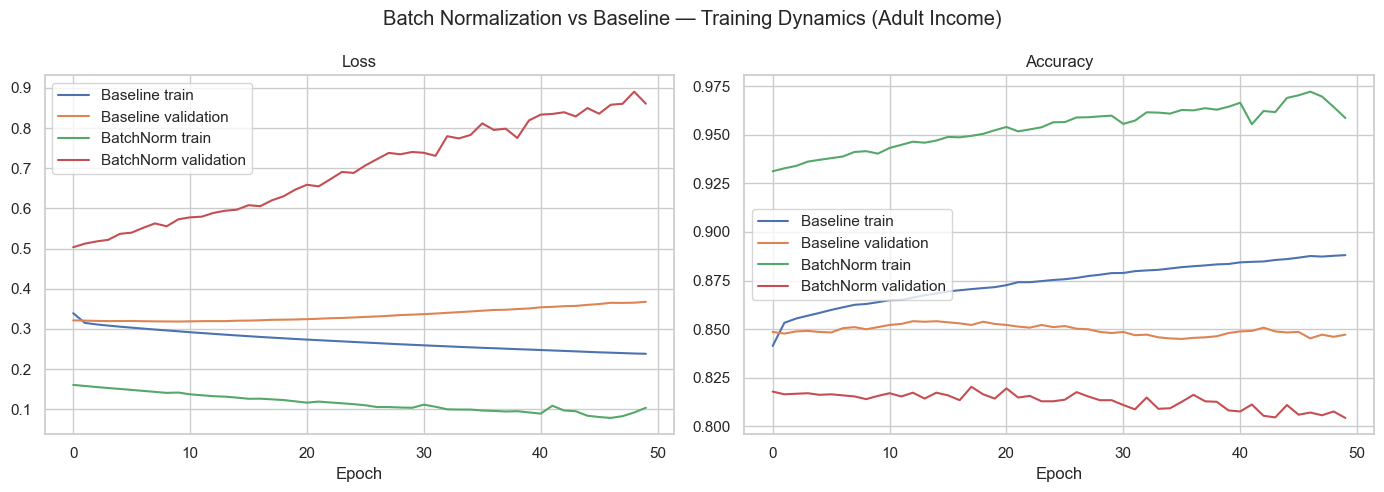

,Test Acc,F1(1)
Model,,
Baseline,0.836705,0.638256
BatchNorm,0.811940,0.575069


In [45]:
keras.utils.set_random_seed(SEED)
history_bn = model_bn.fit(
    X_train, y_train, epochs=50, batch_size=64,
    validation_split=0.1, verbose=1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_base.history["loss"], label="Baseline train")
axes[0].plot(history_base.history["val_loss"], label="Baseline validation")
axes[0].plot(history_bn.history["loss"], label="BatchNorm train")
axes[0].plot(history_bn.history["val_loss"], label="BatchNorm validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history_base.history["accuracy"], label="Baseline train")
axes[1].plot(history_base.history["val_accuracy"], label="Baseline validation")
axes[1].plot(history_bn.history["accuracy"], label="BatchNorm train")
axes[1].plot(history_bn.history["val_accuracy"], label="BatchNorm validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
fig.suptitle("Batch Normalization vs Baseline — Training Dynamics (Adult Income)")
plt.tight_layout()
save_figure("Task_6_3_batchnorm_vs_baseline.png")
plt.show()

bn_metrics, _, _ = predict_metrics(model_bn, X_test, y_test, model_name="BatchNorm")
display(pd.DataFrame([baseline_metrics, bn_metrics]).set_index("Model")[
    ["Test Acc", "F1(1)"]
])

### 6.4 Batch Normalization Position Experiment

Graph saved: Project_Graphs\Task_6_4_batchnorm_position.png


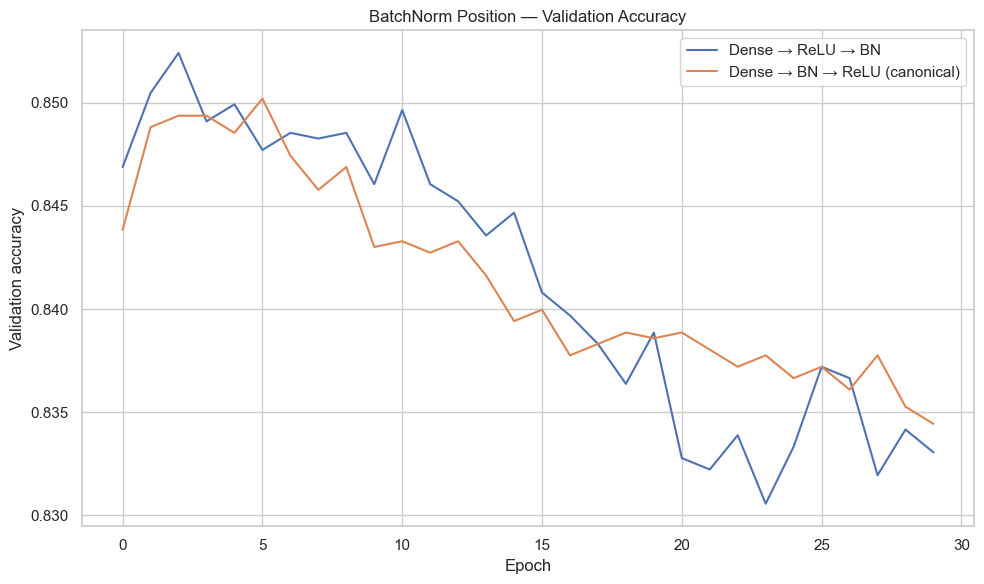

After-activation BN final val accuracy: 0.8331
Before-activation BN final val accuracy: 0.8344
Higher observed result: Before activation / tie
This single run is descriptive; it is not a statistical significance test.


In [46]:
from tensorflow import keras
from tensorflow.keras import layers

def build_bn_position_model(position):
    model = keras.Sequential(name=f"BN_{position}")
    model.add(layers.Input(shape=(input_dim,)))
    for units in [128, 64]:
        model.add(layers.Dense(units, kernel_initializer="he_normal"))
        if position == "after":
            model.add(layers.Activation("relu"))
            model.add(layers.BatchNormalization())
        else:
            model.add(layers.BatchNormalization())
            model.add(layers.Activation("relu"))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

keras.utils.set_random_seed(SEED)
model_bn_after = build_bn_position_model("after")
history_bn_after = model_bn_after.fit(
    X_train, y_train, epochs=30, batch_size=64,
    validation_split=0.1, verbose=0
)

keras.utils.set_random_seed(SEED)
model_bn_before = build_bn_position_model("before")
history_bn_before = model_bn_before.fit(
    X_train, y_train, epochs=30, batch_size=64,
    validation_split=0.1, verbose=0
)

plt.figure(figsize=(10, 6))
plt.plot(history_bn_after.history["val_accuracy"], label="Dense → ReLU → BN")
plt.plot(history_bn_before.history["val_accuracy"], label="Dense → BN → ReLU (canonical)")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("BatchNorm Position — Validation Accuracy")
plt.legend()
plt.tight_layout()
save_figure("Task_6_4_batchnorm_position.png")
plt.show()

after_final = history_bn_after.history["val_accuracy"][-1]
before_final = history_bn_before.history["val_accuracy"][-1]
print(f"After-activation BN final val accuracy: {after_final:.4f}")
print(f"Before-activation BN final val accuracy: {before_final:.4f}")
print("Higher observed result:", "After activation" if after_final > before_final else "Before activation / tie")
print("This single run is descriptive; it is not a statistical significance test.")

### 6.5 Inspect Learned Gamma and Beta

Gamma shape: (128,)
Beta shape: (128,)
Running mean shape: (128,)
Running variance shape: (128,)
Graph saved: Project_Graphs\Task_6_5_batchnorm_gamma_beta.png


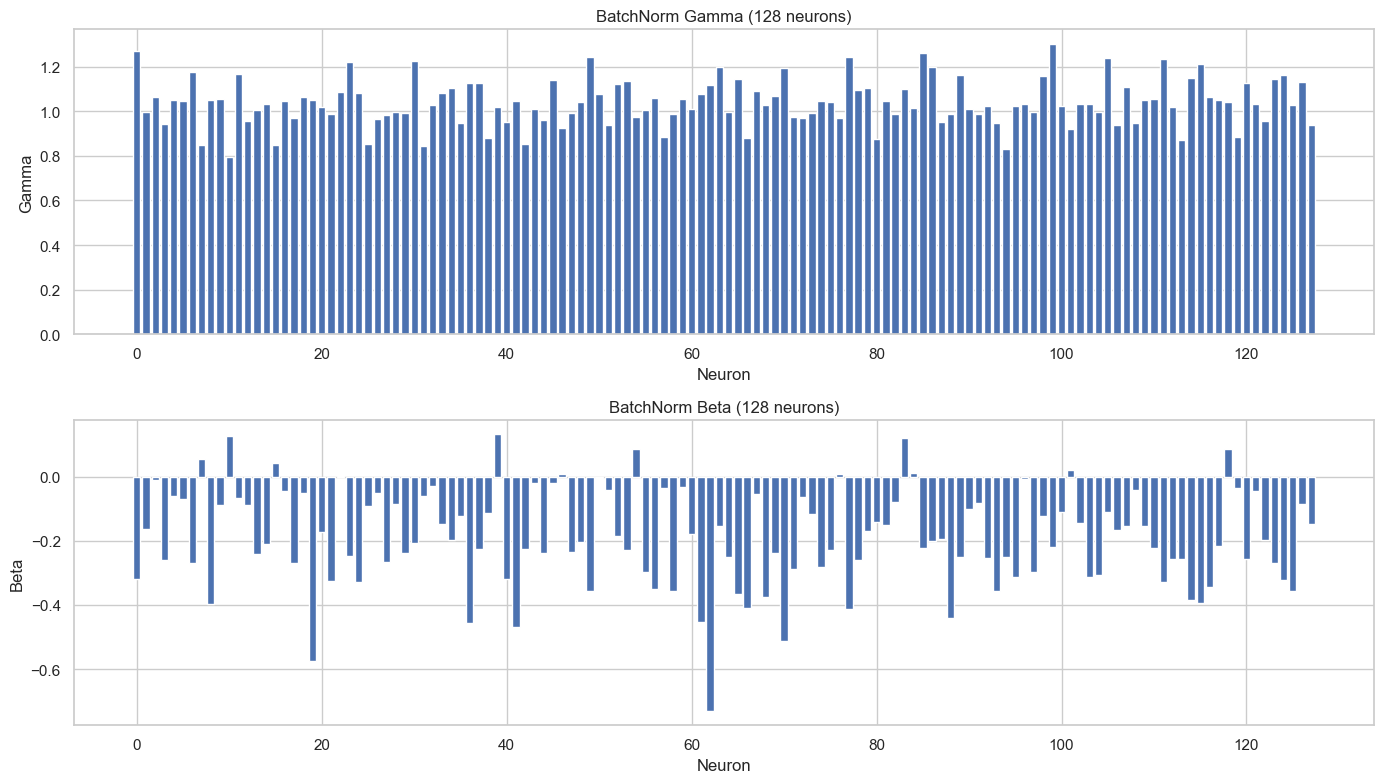

In [47]:
import numpy as np
bn_layer = next(layer for layer in model_bn.layers if isinstance(layer, layers.BatchNormalization))
gamma, beta, running_mean, running_var = bn_layer.get_weights()

print("Gamma shape:", gamma.shape)
print("Beta shape:", beta.shape)
print("Running mean shape:", running_mean.shape)
print("Running variance shape:", running_var.shape)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].bar(np.arange(len(gamma)), gamma)
axes[0].set_title("BatchNorm Gamma (128 neurons)")
axes[0].set_xlabel("Neuron")
axes[0].set_ylabel("Gamma")
axes[1].bar(np.arange(len(beta)), beta)
axes[1].set_title("BatchNorm Beta (128 neurons)")
axes[1].set_xlabel("Neuron")
axes[1].set_ylabel("Beta")
plt.tight_layout()
save_figure("Task_6_5_batchnorm_gamma_beta.png")
plt.show()



# Task 7: Optimizers — Convergence & Final Comparison


# Task 7.1: Define five different optimizers

In [48]:
optimizers = {
    "Vanilla SGD": lambda: keras.optimizers.SGD(),
    "SGD Momentum": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop": lambda: keras.optimizers.RMSprop(),
    "Adam Default": lambda: keras.optimizers.Adam(),
    "Adam Explicit": lambda: keras.optimizers.Adam(
        learning_rate=0.001, beta_1=0.9, beta_2=0.999
    )
}
print("Total optimizers:", len(optimizers))

Total optimizers: 5


In [49]:
optimizer_models = {}
optimizer_histories = {}

for optimizer_name, optimizer_factory in optimizers.items():
    print(f"Training: {optimizer_name}")
    keras.utils.set_random_seed(SEED)
    model = build_ann(
        input_dim=input_dim,
        hidden_units=(128, 64),
        activation="relu",
        initializer="he_normal",
        use_batch_norm=True,
        optimizer=optimizer_factory(),
        loss="binary_crossentropy"
    )
    history = model.fit(
        X_train, y_train,
        epochs=50, batch_size=64,
        validation_split=0.1, verbose=0
    )
    optimizer_models[optimizer_name] = model
    optimizer_histories[optimizer_name] = history
    print(f"{optimizer_name}: {len(history.history['loss'])}/50 epochs completed")

assert len(optimizer_models) == 5
assert all(len(h.history["loss"]) == 50 for h in optimizer_histories.values())
print("All five optimizer models completed 50 epochs.")

Training: Vanilla SGD
Vanilla SGD: 50/50 epochs completed
Training: SGD Momentum
SGD Momentum: 50/50 epochs completed
Training: RMSprop
RMSprop: 50/50 epochs completed
Training: Adam Default
Adam Default: 50/50 epochs completed
Training: Adam Explicit
Adam Explicit: 50/50 epochs completed
All five optimizer models completed 50 epochs.


## Task 7.2: Optimizer Convergence Plot


Graph saved: Project_Graphs\Task_7_2_optimizer_convergence.png


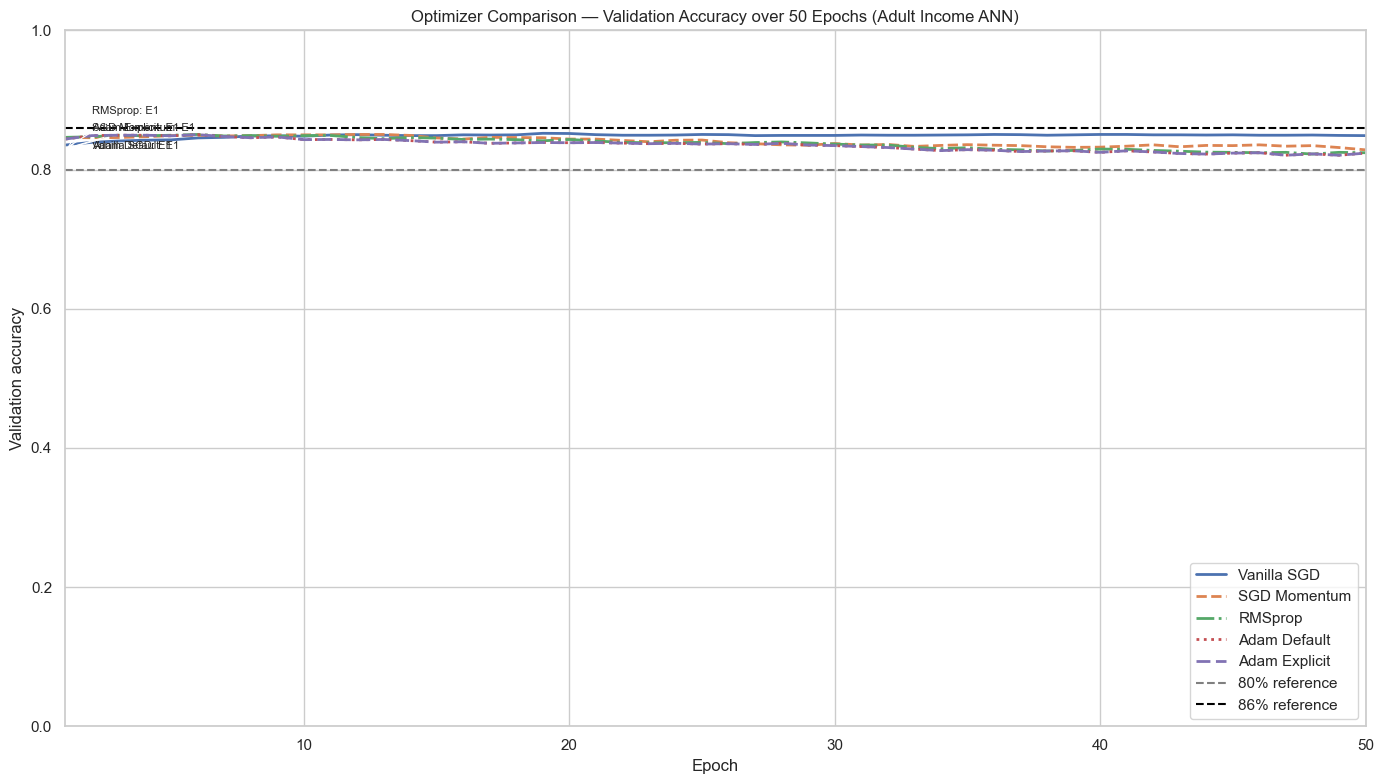

,Optimizer,Final validation accuracy,Best validation accuracy,Epochs completed
0,Vanilla SGD,0.848812,0.852128,50
1,SGD Momentum,0.828358,0.850470,50
2,RMSprop,0.824212,0.850470,50
3,Adam Default,0.823659,0.850194,50
4,Adam Explicit,0.823659,0.850194,50


In [50]:
line_styles = ["-", "--", "-.", ":", (0, (5, 2))]
plt.figure(figsize=(14, 8))

for (name, history), style in zip(optimizer_histories.items(), line_styles):
    val_acc = history.history["val_accuracy"]
    epochs = np.arange(1, len(val_acc) + 1)
    plt.plot(epochs, val_acc, linestyle=style, linewidth=2, label=name)

    crossing = next((int(e) for e, score in zip(epochs, val_acc) if score >= 0.83), None)
    if crossing is not None:
        plt.annotate(
            f"{name}: E{crossing}",
            xy=(crossing, 0.83),
            xytext=(crossing + 1, min(0.98, 0.83 + 0.025 * (list(optimizer_histories).index(name) % 3))),
            fontsize=8,
            arrowprops={"arrowstyle": "->", "lw": 0.8}
        )
    else:
        print(f"{name} did not cross 83% validation accuracy.")

plt.axhline(0.80, color="gray", linestyle="--", label="80% reference")
plt.axhline(0.86, color="black", linestyle="--", label="86% reference")
plt.title("Optimizer Comparison — Validation Accuracy over 50 Epochs (Adult Income ANN)")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.xlim(1, 50)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
save_figure("Task_7_2_optimizer_convergence.png")
plt.show()

optimizer_validation_summary = pd.DataFrame([
    {"Optimizer": name,
     "Final validation accuracy": hist.history["val_accuracy"][-1],
     "Best validation accuracy": max(hist.history["val_accuracy"]),
     "Epochs completed": len(hist.history["loss"])}
    for name, hist in optimizer_histories.items()
])
display(optimizer_validation_summary.sort_values("Final validation accuracy", ascending=False))


## Task 7.3: WHY Adam Dominates — Optimizer Comparison

### 1. Vanilla SGD
- Uses a fixed learning rate for all parameters.
- Updates weights using the current gradient.
- Convergence can be slow on sparse and high-dimensional One-Hot Encoded features.
- Does not adapt the learning rate separately for each parameter.

### 2. SGD with Momentum
- Uses a velocity term to remember previous gradients.
- Formula: `v = β × v + learning_rate × gradient`
- Reduces oscillations and can speed up learning.
- Still uses the same learning rate for all parameters.

### 3. RMSprop
- Maintains a moving average of squared gradients.
- Adapts the learning rate separately for each parameter.
- Helps when gradients have different magnitudes.
- Can perform well on non-stationary problems.

### 4. Adam
- Combines Momentum and RMSprop.
- First moment (`m`) stores the moving average of gradients.
- Second moment (`v`) stores the moving average of squared gradients.
- Uses bias correction because both moments start at zero.

Weight update:

`θ = θ − learning_rate × m̂ / (√v̂ + ε)`

Adam often converges quickly and performs well with different learning rates.

### 5. Adam Explicit
- Uses the same learning rate and beta values as Keras Adam defaults.
- Learning rate = 0.001
- Beta 1 = 0.9
- Beta 2 = 0.999
- Helps verify that explicitly specified Adam parameters match the default configuration.

In [51]:
optimizer_metric_rows = []
optimizer_crossing_epochs = {}
for name, model in optimizer_models.items():
    row, _, _ = predict_metrics(model, X_test, y_test, model_name=name)
    optimizer_metric_rows.append(row)
    vals = optimizer_histories[name].history["val_accuracy"]
    optimizer_crossing_epochs[name] = next(
        (i + 1 for i, value in enumerate(vals) if value >= 0.83), np.nan
    )

optimizer_metrics_df = pd.DataFrame(optimizer_metric_rows).set_index("Model")
display(optimizer_metrics_df[["Test Acc", "Prec(1)", "Recall(1)", "F1(1)", "ROC-AUC"]])

best_optimizer_f1 = optimizer_metrics_df["F1(1)"].idxmax()
fastest_optimizer = min(
    optimizer_crossing_epochs,
    key=lambda name: optimizer_crossing_epochs[name]
    if not np.isnan(optimizer_crossing_epochs[name]) else float("inf")
)
print("Highest test class-1 F1:", best_optimizer_f1,
      f"({optimizer_metrics_df.loc[best_optimizer_f1, 'F1(1)']:.4f})")
print("Fastest to cross 83% validation accuracy:", fastest_optimizer,
      "| epoch:", optimizer_crossing_epochs[fastest_optimizer])

,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
Model,,,,,
Vanilla SGD,0.852736,0.735021,0.634701,0.681187,0.908386
SGD Momentum,0.826976,0.667824,0.600803,0.632543,0.880205
RMSprop,0.821227,0.666489,0.557984,0.607429,0.873342
Adam Default,0.817358,0.659632,0.543711,0.596088,0.871969
Adam Explicit,0.817358,0.659632,0.543711,0.596088,0.871969


Highest test class-1 F1: Vanilla SGD (0.6812)
Fastest to cross 83% validation accuracy: Vanilla SGD | epoch: 1



## Task 7.4: Learning Rate Sensitivity — SGD vs Adam

**SGD learning rates:** 0.0001, 0.001, 0.01, 0.1

**Adam learning rates:** 0.0001, 0.001, 0.01

All models will use the same ANN architecture and training configuration so that the learning rate is the main variable.


## Train 7 models

Training SGD learning rate: 0.0001
Training SGD learning rate: 0.001
Training SGD learning rate: 0.01
Training SGD learning rate: 0.1
Training Adam learning rate: 0.0001
Training Adam learning rate: 0.001
Training Adam learning rate: 0.01
Graph saved: Project_Graphs\Task_7_4_learning_rate_sensitivity.png


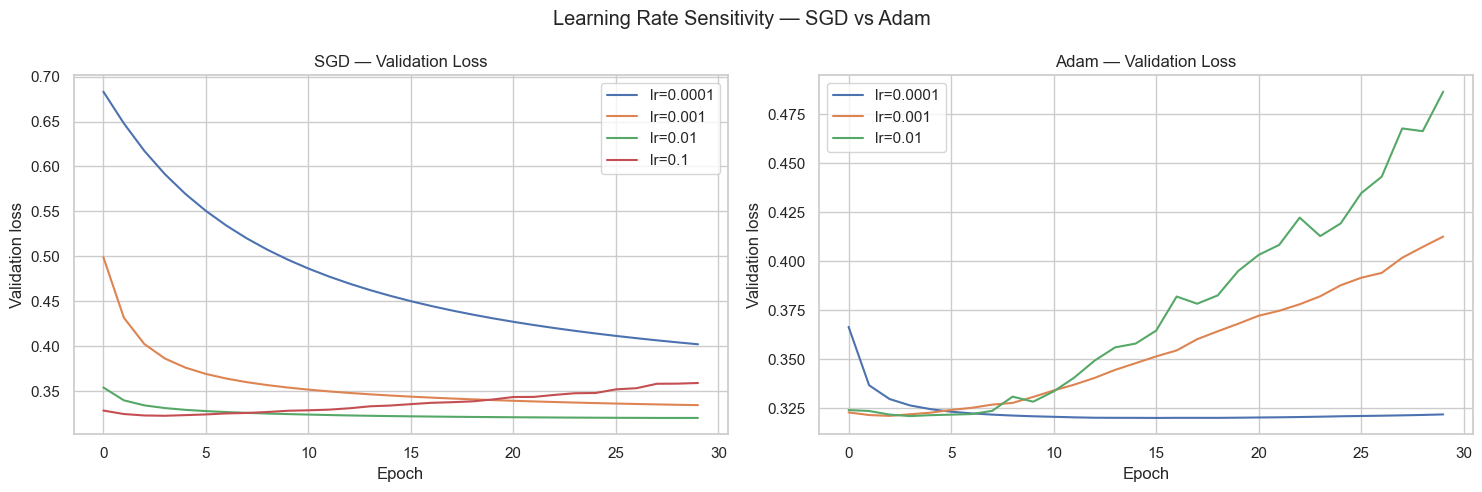

In [52]:
sgd_lrs = [0.0001, 0.001, 0.01, 0.1]
adam_lrs = [0.0001, 0.001, 0.01]
lr_histories = {"SGD": {}, "Adam": {}}

for lr in sgd_lrs:
    print("Training SGD learning rate:", lr)
    keras.utils.set_random_seed(SEED)
    model = build_ann(
        input_dim=input_dim, activation="relu", initializer="he_normal",
        use_batch_norm=True,
        optimizer=keras.optimizers.SGD(learning_rate=lr),
        loss="binary_crossentropy"
    )
    lr_histories["SGD"][lr] = model.fit(
        X_train, y_train, epochs=30, batch_size=64,
        validation_split=0.1, verbose=0
    )

for lr in adam_lrs:
    print("Training Adam learning rate:", lr)
    keras.utils.set_random_seed(SEED)
    model = build_ann(
        input_dim=input_dim, activation="relu", initializer="he_normal",
        use_batch_norm=True,
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy"
    )
    lr_histories["Adam"][lr] = model.fit(
        X_train, y_train, epochs=30, batch_size=64,
        validation_split=0.1, verbose=0
    )

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for lr, hist in lr_histories["SGD"].items():
    axes[0].plot(hist.history["val_loss"], label=f"lr={lr}")
axes[0].set_title("SGD — Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation loss")
axes[0].legend()

for lr, hist in lr_histories["Adam"].items():
    axes[1].plot(hist.history["val_loss"], label=f"lr={lr}")
axes[1].set_title("Adam — Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation loss")
axes[1].legend()

fig.suptitle("Learning Rate Sensitivity — SGD vs Adam")
plt.tight_layout()
save_figure("Task_7_4_learning_rate_sensitivity.png")
plt.show()

## Task 7.5 — Final combined ANN using the best configuration

The assignment's recommended combined architecture is ReLU + He Normal + BatchNorm + Adam. Use weighted BCE only if it improved class-1 F1 in the earlier comparison. Train for 80 epochs and evaluate on the held-out test set.

In [53]:
use_weighted_final = (
    loss_metrics_df.loc["Weighted BCE", "F1(1)"] >
    loss_metrics_df.loc["Baseline BCE", "F1(1)"]
)
final_loss = "binary_crossentropy"  # BCE is retained; class weighting handles imbalance if useful.

keras.utils.set_random_seed(SEED)
final_model = build_ann(
    input_dim=input_dim,
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="adam",
    loss=final_loss
)

final_fit_kwargs = {}
if use_weighted_final:
    final_fit_kwargs["class_weight"] = class_weight_dict
    print("Weighted BCE improved F1: final model will use class weights.")
else:
    print("Weighted BCE did not improve F1: final model will use standard BCE.")

history_final = final_model.fit(
    X_train, y_train,
    epochs=80, batch_size=64,
    validation_split=0.1,
    verbose=1,
    **final_fit_kwargs
)

final_metrics, final_prob, final_pred = predict_metrics(
    final_model, X_test, y_test, model_name="Final Combined"
)
print(classification_report(y_test, final_pred, target_names=["<=50K (0)", ">50K (1)"]))
display(pd.DataFrame([final_metrics]).set_index("Model"))

Weighted BCE improved F1: final model will use class weights.
Epoch 1/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7928 - loss: 0.4018 - val_accuracy: 0.8021 - val_loss: 0.3836
Epoch 2/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8086 - loss: 0.3749 - val_accuracy: 0.8027 - val_loss: 0.3822
Epoch 3/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8125 - loss: 0.3667 - val_accuracy: 0.8029 - val_loss: 0.3818
Epoch 4/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8165 - loss: 0.3602 - val_accuracy: 0.8021 - val_loss: 0.3802
Epoch 5/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8199 - loss: 0.3544 - val_accuracy: 0.8024 - val_loss: 0.3793
Epoch 6/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8234 - loss: 0.3490 - val_accuracy: 0.8054 - val_loss: 0.3778
Epoch 7/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8260 - loss: 0.3436 - val_accuracy: 0.8062 - val_loss: 0.3781
Epoch 8/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s

,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
Model,,,,,
Final Combined,0.819569,0.650841,0.586976,0.617261,0.867795


## Task 7.6 — Full results comparison table and ROC curves

Compare the required model groups: Baseline, best Activation, best Initializer, Weighted BCE, Focal Loss, BatchNorm and Final Combined. Metrics are computed on the same held-out test set.

In [54]:
def best_model_from_group(model_dict, metric_name="F1(1)"):
    rows = []
    for name, model in model_dict.items():
        row, _, _ = predict_metrics(model, X_test, y_test, model_name=name)
        rows.append(row)
    frame = pd.DataFrame(rows).set_index("Model")
    return frame[metric_name].idxmax(), frame

best_activation_name, activation_test_metrics = best_model_from_group(
    activation_models, "F1(1)"
)
best_initializer_name, initializer_test_metrics = best_model_from_group(
    initializer_models, "F1(1)"
)

required_models = {
    "Baseline (Task 2)": model_base,
    f"Best Activation ({best_activation_name})": activation_models[best_activation_name],
    f"Best Initializer ({best_initializer_name})": initializer_models[best_initializer_name],
    "Weighted BCE (Task 5)": model_wbce,
    "Focal Loss (Task 5)": model_focal,
    "BatchNorm (Task 6)": model_bn,
    "Final Combined (Task 7)": final_model
}

results_rows = []
for display_name, model in required_models.items():
    row, _, _ = predict_metrics(model, X_test, y_test, model_name=display_name)
    if display_name == "Baseline (Task 2)":
        activation, init, loss_name, bn, opt = "ReLU", "Glorot Uniform", "BCE", "No", "Adam"
    elif display_name.startswith("Best Activation"):
        activation, init, loss_name, bn, opt = best_activation_name, "Glorot Uniform", "BCE", "No", "Adam"
    elif display_name.startswith("Best Initializer"):
        activation, init, loss_name, bn, opt = "ReLU", best_initializer_name, "BCE", "No", "Adam"
    elif display_name.startswith("Weighted BCE"):
        activation, init, loss_name, bn, opt = "ReLU", "He Normal", "Weighted BCE", "No", "Adam"
    elif display_name.startswith("Focal Loss"):
        activation, init, loss_name, bn, opt = "ReLU", "He Normal", "Focal Loss", "No", "Adam"
    elif display_name.startswith("BatchNorm"):
        activation, init, loss_name, bn, opt = "ReLU", "He Normal", "BCE", "Yes", "Adam"
    else:
        activation, init = "ReLU", "He Normal"
        loss_name = "Weighted BCE" if use_weighted_final else "BCE"
        bn, opt = "Yes", "Adam"

    results_rows.append({
        "Model": display_name,
        "Activation": activation,
        "Init": init,
        "Loss": loss_name,
        "BatchNorm": bn,
        "Optimizer": opt,
        "Test Acc": row["Test Acc"],
        "Prec(1)": row["Prec(1)"],
        "Recall(1)": row["Recall(1)"],
        "F1(1)": row["F1(1)"],
        "ROC-AUC": row["ROC-AUC"]
    })

results_df = pd.DataFrame(results_rows)
display(
    results_df.style
    .highlight_max(subset=["F1(1)", "ROC-AUC"], color="#ffcccc")
    .format({c: "{:.4f}" for c in ["Test Acc", "Prec(1)", "Recall(1)", "F1(1)", "ROC-AUC"]})
)

,Model,Activation,Init,Loss,BatchNorm,Optimizer,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Baseline (Task 2),ReLU,Glorot Uniform,BCE,No,Adam,0.8367,0.7078,0.5812,0.6383,0.8871
1,Best Activation (sigmoid),sigmoid,Glorot Uniform,BCE,No,Adam,0.8531,0.7501,0.6106,0.6732,0.9119
2,Best Initializer (glorot_uniform),ReLU,glorot_uniform,BCE,No,Adam,0.8367,0.7078,0.5812,0.6383,0.8871
3,Weighted BCE (Task 5),ReLU,He Normal,Weighted BCE,No,Adam,0.7978,0.5656,0.7939,0.6606,0.8835
4,Focal Loss (Task 5),ReLU,He Normal,Focal Loss,No,Adam,0.8190,0.7536,0.4010,0.5234,0.8752
5,BatchNorm (Task 6),ReLU,He Normal,BCE,Yes,Adam,0.8119,0.6536,0.5134,0.5751,0.8613
6,Final Combined (Task 7),ReLU,He Normal,Weighted BCE,Yes,Adam,0.8196,0.6508,0.5870,0.6173,0.8678


Graph saved: Project_Graphs\Task_7_6_roc_curve_comparison.png


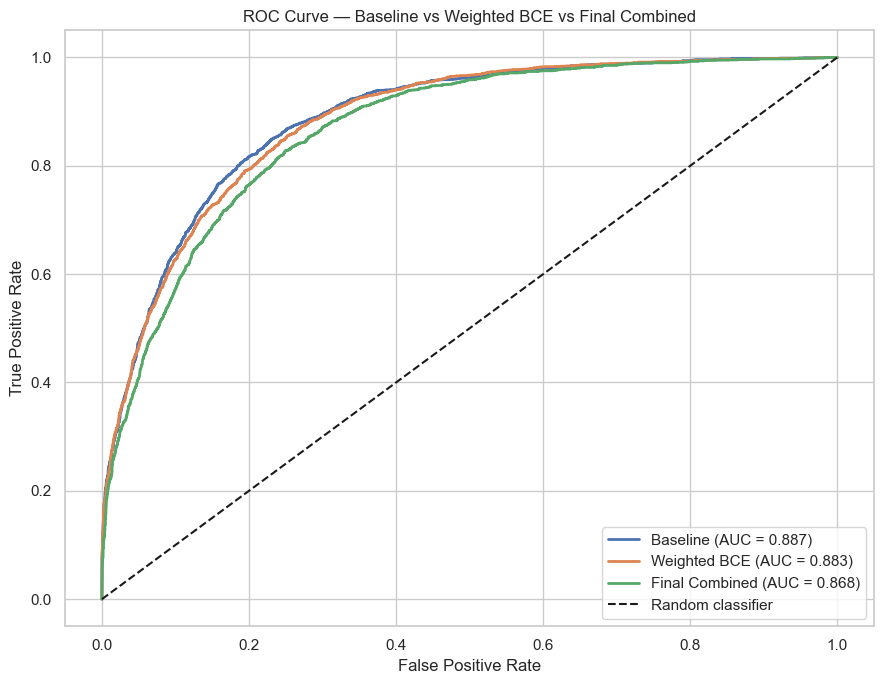

Largest measured individual F1 result: Activation (0.6732)
This is a descriptive comparison across experiments; changes in random initialization and training runs can also affect measured performance.


In [55]:
roc_models = {
    "Baseline": model_base,
    "Weighted BCE": model_wbce,
    "Final Combined": final_model
}

plt.figure(figsize=(9, 7))
for name, model in roc_models.items():
    probabilities = model.predict(X_test, verbose=0).ravel()
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Baseline vs Weighted BCE vs Final Combined")
plt.legend()
plt.tight_layout()
save_figure("Task_7_6_roc_curve_comparison.png")
plt.show()

best_individual_technique = max(
    [
        ("Activation", activation_test_metrics["F1(1)"].max()),
        ("Initializer", initializer_test_metrics["F1(1)"].max()),
        ("Weighted BCE", loss_metrics_df.loc["Weighted BCE", "F1(1)"]),
        ("Focal Loss", loss_metrics_df.loc["Focal Loss", "F1(1)"]),
        ("Batch Normalization", bn_metrics["F1(1)"])
    ],
    key=lambda item: item[1]
)
print("Largest measured individual F1 result:", best_individual_technique[0],
      f"({best_individual_technique[1]:.4f})")
print("This is a descriptive comparison across experiments; changes in random initialization "
      "and training runs can also affect measured performance.")

## Final Project Summary

This project completed the seven assignment tasks on the Adult Income dataset:

- Data cleaning, target encoding, EDA, one-hot encoding, scaling and stratified split.
- Baseline multilayer perceptron and complete classification evaluation.
- Activation-function comparison and gradient/dead-neuron diagnostics.
- Weight-initializer comparison and weight-distribution analysis.
- BCE, MSE, weighted BCE and focal-loss experiments.
- Batch Normalization architecture, placement and learned-parameter inspection.
- Five-optimizer comparison, learning-rate sensitivity, final combined ANN, metrics table and ROC curves.

### Saved figures

All figures created by this notebook are saved as 300-DPI PNG files inside `Project_Graphs/`. Run the notebook from top to bottom to regenerate the folder and all charts.

### Submission checklist

1. Run **Kernel → Restart Kernel and Run All** and confirm there are no errors.
2. Confirm `adult.csv` and `DL_PR2.ipynb` are in the same project directory.
3. Check the `Project_Graphs/` folder contains the generated plots.
4. Save/export the notebook as HTML if required by your instructor.
5. Add the notebook, dataset (if permitted by the dataset license/course rules), plots and README to your GitHub repository.